# Práctica 2. Análisis Exploratorio de Datos (EDA) y preparación de datasets

**Equipo:** Chagoya Gómez Diego Francisco, Guitérrez Ocon Eber Rodrigo, Molina Flores Enrique Sebastián, 
Navarro Corona Rubén, Rodríguez Pedraza Emiliano **Fecha:** 15/10/2026

**Datasets:** Titanic (objetivo: supervivencia) y Adult Income (objetivo: ingreso superior a 50K).

> Declaración de uso de IA generativa. 
> Nos apoyamos en la IA para aprender a instalar pandas e importar los dataset, en el caso del dataset Adult ha convertirlo en .csv y además de ayudarnos a graficar los resultados.

**Contenido:** 0. Decisiones · 1. Comprensión del dominio · 2. Data profiling · 3. EDA · 4. Separación train/test ·
5. Imputación · 6. Outliers (winsorización) · 7. Desbalance · 8. Modelado y evaluación · 9. Conclusiones

## 0. Decisiones de diseño 


| Decisión | Valor elegido | Motivo |
|---|---|---|
| Clasificador | Regresión logística (con escalado y one-hot) | Es sensible a la escala, a los outliers y a los faltantes, por lo que los efectos del preprocesamiento se ven con claridad. Es rápida y tiene `class_weight`. |
| Partición | 75 % train / 25 % test, estratificada, `SEED = 42` | Mantiene la proporción de clases en ambos conjuntos y hace reproducible el resultado. |
| Orden anti-fuga | Primero se separa; imputación, winsorización y remuestreo se calculan **solo con train** | Si se calcularan con todos los datos, el test influiría en el entrenamiento y las métricas serían optimistas. |
| Winsorización | IQR con k = 1.5 y percentiles 1-99 | k = 1.5 es la convención de Tukey; 1-99 recorta solo el 1 % más extremo de cada cola. |
| Métricas | precision, recall, F1 (clase positiva), balanced accuracy, ROC-AUC y accuracy | El enunciado advierte que accuracy sola engaña. |
| Dos datasets | Titanic y Adult | Ambos tienen variables mixtas, faltantes, outliers y desbalance (IR > 1.5). |


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.impute import KNNImputer
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score, ConfusionMatrixDisplay)

try:
    from IPython.display import display
except ImportError:          # si se ejecuta como script
    display = print

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- Parámetros globales (decisiones del equipo, ver sección 0) ----
SEED = 42            # semilla única para que todo sea reproducible
TEST_SIZE = 0.25     # 75 % entrenamiento / 25 % prueba
K_IQR = 1.5          # multiplicador del rango intercuartílico (convención de Tukey)
PCT_INF, PCT_SUP = 1, 99   # percentiles extremos para winsorizar

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.options.display.float_format = "{:,.3f}".format
sns.set_theme(style="whitegrid", context="notebook")

def guardar(fig, nombre):
    # guarda cada figura en la carpeta figuras/ (útil para el informe y la presentación)
    os.makedirs("figuras", exist_ok=True)
    fig.savefig(os.path.join("figuras", nombre + ".png"), dpi=130, bbox_inches="tight")

def guardar_tabla(df, nombre):
    os.makedirs("resultados", exist_ok=True)
    df.to_csv(os.path.join("resultados", nombre + ".csv"))

## 1. Comprensión del dominio del dataset

In [2]:
def ruta(nombre):
    # busca el archivo primero en data/ y después en la carpeta actual
    for carpeta in ("data", "."):
        p = os.path.join(carpeta, nombre)
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"No encontré {nombre}. Colócalo en la carpeta data/.")

adult_raw = pd.read_csv(ruta("adult.csv"))
titanic_raw = pd.read_csv(ruta("train.csv"))

# Variable objetivo numérica (1 = clase positiva/minoritaria) para análisis y modelado
adult = adult_raw.assign(income_bin=(adult_raw["income"] == ">50K").astype(int))
titanic = titanic_raw.assign(Cabin_presente=titanic_raw["Cabin"].notna().astype(int))

print("Adult   :", adult_raw.shape, "-> filas, columnas")
print("Titanic :", titanic_raw.shape, "-> filas, columnas")
display(titanic_raw.head(3))
display(adult_raw.head(3))

Adult   : (48842, 15) -> filas, columnas
Titanic : (891, 12) -> filas, columnas


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000,0,0,STON/O2. 3101282,7.925,NaN,S


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K


### 1.1 Ficha de cada dataset

| | **Titanic** | **Adult Income** |
|---|---|---|
| Fuente | Kaggle, competencia *Titanic - Machine Learning from Disaster*, archivo `train.csv` | UCI Machine Learning Repository, *Adult* (Becker y Kohavi, 1996). DOI: 10.24432/C5XW20 |
| Licencia | Términos y reglas de la competencia en Kaggle. **Pendiente de verificar en la página antes de entregar.** | CC BY 4.0 (verificado en la ficha de UCI) |
| Filas × columnas | 891 × 12 | 48,842 × 15 (se unieron `adult.data` y `adult.test`) |
| Unidad de análisis | Un pasajero | Una persona registrada en un censo (datos de 1994, según el archivo `adult.names`) |
| Variable objetivo | `Survived` (1 = sobrevivió; 38.4 %) | `income` (`>50K` = 1; 23.9 %) |
| Clase positiva | Sobrevivió | Ingreso mayor a 50K |

**Atributos de Titanic.** `PassengerId` (identificador), `Pclass` (clase del boleto: 1, 2 o 3; aproxima el nivel
socioeconómico), `Name`, `Sex`, `Age` (años; fraccionaria si es menor de 1), `SibSp` (hermanos o cónyuge a bordo),
`Parch` (padres o hijos a bordo), `Ticket` (número de boleto), `Fare` (tarifa), `Cabin` (cabina) y `Embarked`
(puerto: C = Cherbourg, Q = Queenstown, S = Southampton).

**Atributos de Adult.** `age`, `workclass` (tipo de empleador), `fnlwgt` (peso muestral del censo: cuántas personas
representa el registro), `education` y `education-num` (nivel educativo en texto y en número), `marital-status`,
`occupation`, `relationship` (rol en el hogar), `race`, `sex`, `capital-gain` y `capital-loss` (ganancias y pérdidas de
capital), `hours-per-week`, `native-country` e `income`.

### 1.2 Preguntas 

**¿Qué representa cada fila?** Titanic: un pasajero (891 de los 1,309 registros que Kaggle reparte entre `train.csv`
y `test.csv`). Adult: una persona del censo.

**¿La variable objetivo estaría disponible en un escenario real?** No al momento de predecir. En Titanic el desenlace
solo se conoce después del naufragio, así que el problema es retrospectivo y didáctico. En Adult el ingreso real
tampoco se conoce de antemano en un uso como el *scoring* de crédito; se estimaría a partir de otros atributos.

**¿Existen identificadores o variables con fuga de información?**
- Identificadores: `PassengerId` y `Name` (únicos) y, casi, `Ticket` (76 % de valores únicos). No deben entrar al modelo.
- Posible fuga en Titanic: `Cabin`. El 66.7 % de quienes tienen cabina registrada sobrevivió, frente al 30.0 % de quienes
  no la tienen (ver sección 3). Que la cabina esté registrada puede reflejar cómo se recopilaron los datos *después* del
  hecho y no una característica previa al viaje. Por eso se usa solo la letra de cubierta (`Deck`) y se marca explícitamente
  cuándo falta.
- Adult: no hay una variable que revele el ingreso de forma directa (el análisis de la sección 2 no encuentra ninguna con
  asociación sospechosamente alta). `fnlwgt` es un peso muestral, no un atributo de la persona, y `education` es idéntica
  a `education-num` (ver sección 2); `relationship` y `marital-status` funcionan como indicadores indirectos del sexo
  (por ejemplo, *Husband* y *Wife*).

**¿Qué decisiones podrían afectar de forma desigual a distintos grupos?**
- Titanic: sexo, clase del boleto y edad. Un modelo entrenado con estos datos reproduce las prioridades históricas de
  evacuación (mujeres, niños y primera clase); usarlo para asignar recursos desfavorecería a hombres y a pasajeros de tercera clase.
- Adult: sexo, raza, país de origen y edad. Los datos son de 1994 y reflejan desigualdades históricas de ingreso (en este
  dataset el 10.9 % de las mujeres y el 30.4 % de los hombres supera los 50K). Un modelo que decida crédito, empleo o precios con
  estos atributos puede discriminar. En la sección 7 se mide qué ocurre por sexo con cada técnica.


## 2. Data profiling

Se perfilan las variables **crudas** (antes de cualquier limpieza). Para cada tipo de variable se reporta lo que pide
el enunciado: tipo, válidos y ausentes, porcentaje de ausencia, únicos, estadísticos, percentiles, asimetría, moda,
frecuencias, dominio y valores potencialmente inválidos (la regla usada para cada variable aparece en la tabla).

In [3]:
# ---------- Reglas de valores potencialmente inválidos (dominio esperado) ----------
REGLAS = {
    "Titanic": {
        "Age":   ("edad <= 0 o > 100", lambda s: (s <= 0) | (s > 100)),
        "SibSp": ("valor negativo", lambda s: s < 0),
        "Parch": ("valor negativo", lambda s: s < 0),
        "Fare":  ("tarifa <= 0 (0 = posible dato faltante codificado)", lambda s: s <= 0),
    },
    "Adult": {
        "age":            ("edad < 17 o > 100 (el dataset filtra edad > 16)", lambda s: (s < 17) | (s > 100)),
        "fnlwgt":         ("peso muestral <= 0", lambda s: s <= 0),
        "education-num":  ("fuera del rango 1-16", lambda s: (s < 1) | (s > 16)),
        "capital-gain":   ("= 99999 (valor tope codificado)", lambda s: s == 99999),
        "capital-loss":   ("valor negativo", lambda s: s < 0),
        "hours-per-week": ("= 99 (valor tope) o < 1", lambda s: (s == 99) | (s < 1)),
    },
}

def perfil_numerico(df, cols, reglas):
    filas = []
    for c in cols:
        s = df[c]
        v = s.dropna()
        fila = {
            "variable": c, "tipo": str(s.dtype),
            "validos": len(v), "ausentes": int(s.isna().sum()),
            "%ausente": 100 * s.isna().mean(), "unicos": int(s.nunique()),
            "min": v.min(), "p1": v.quantile(.01), "p5": v.quantile(.05), "p25": v.quantile(.25),
            "mediana": v.median(), "media": v.mean(), "p75": v.quantile(.75),
            "p95": v.quantile(.95), "p99": v.quantile(.99), "max": v.max(),
            "desv.est": v.std(), "asimetria": v.skew(),
        }
        if c in reglas:
            desc, f = reglas[c]
            fila["regla_invalido"] = desc
            fila["n_invalidos"] = int(f(v).sum())
        else:
            fila["regla_invalido"] = "-"
            fila["n_invalidos"] = 0
        filas.append(fila)
    return pd.DataFrame(filas).set_index("variable")

def perfil_categorico(df, cols):
    filas = []
    for c in cols:
        s = df[c]
        v = s.dropna()
        vc = v.value_counts()
        dominio = ", ".join(map(str, vc.index[:8])) + (" ..." if len(vc) > 8 else "")
        filas.append({
            "variable": c, "tipo": str(s.dtype),
            "validos": len(v), "ausentes": int(s.isna().sum()),
            "%ausente": 100 * s.isna().mean(), "unicos": int(s.nunique()),
            "moda": vc.index[0], "frec_moda": int(vc.iloc[0]), "%moda": 100 * vc.iloc[0] / len(v),
            "dominio (primeras categorias)": dominio,
        })
    return pd.DataFrame(filas).set_index("variable")

def frecuencias(df, col, top=12):
    vc = df[col].value_counts(dropna=False)
    t = pd.DataFrame({"conteo": vc, "%": 100 * vc / len(df)})
    t.index = t.index.map(lambda x: "(ausente)" if pd.isna(x) else x)
    return t.head(top)

def inconsistencias_categoricas(df, cols):
    # busca categorías duplicadas por mayúsculas/espacios y símbolos de faltante disfrazados
    simbolos = {"?", "", "nan", "none", "null", "unknown", "n/a", "na", "-"}
    filas = []
    for c in cols:
        v = df[c].dropna().astype(str)
        norm = v.str.strip().str.lower()
        filas.append({
            "variable": c,
            "unicos_originales": v.nunique(),
            "unicos_normalizados": norm.nunique(),
            "con_espacios_extremos": int((v != v.str.strip()).sum()),
            "simbolos_de_faltante": int(norm.isin(simbolos).sum()),
        })
    return pd.DataFrame(filas).set_index("variable")

def cramers_v(x, y):
    tabla = pd.crosstab(x.astype(object).where(x.notna(), "(ausente)"), y)
    chi2 = stats.chi2_contingency(tabla, correction=False)[0]
    k = min(tabla.shape) - 1
    return float(np.sqrt(chi2 / (tabla.values.sum() * k))) if k > 0 else np.nan

def chequeos_generales(df, ids, num_corr, num_asoc, cat_asoc, y):
    # 1) duplicados
    sin_id = df.drop(columns=[c for c in ids if c in df.columns])
    print("Filas duplicadas (ignorando columnas identificadoras):", int(sin_id.duplicated().sum()))
    # 2) constantes, casi constantes e identificadores
    r = pd.DataFrame({
        "%valor_mas_frecuente": [100 * df[c].value_counts(normalize=True).iloc[0] for c in df.columns],
        "ratio_unicos": [df[c].nunique() / df[c].notna().sum() for c in df.columns],
        "%ausente": 100 * df.isna().mean().values,
    }, index=df.columns)
    r["alerta"] = np.select(
        [df.nunique().values <= 1,
         r["%valor_mas_frecuente"] >= 95,
         r["ratio_unicos"] >= 0.9,
         r["ratio_unicos"] >= 0.5],
        ["constante", "casi constante (>=95 %)", "identificador (>=90 % únicos)", "alta cardinalidad"],
        default="")
    print("\nColumnas con alguna alerta (constantes, casi constantes, identificadores):")
    display(r[r["alerta"] != ""].sort_values("ratio_unicos", ascending=False))
    # 3) correlaciones elevadas (Spearman, |rho| >= 0.7)
    corr = df[num_corr].corr(method="spearman")
    pares = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
    altas = pares[pares.abs() >= 0.7]
    print("\nPares numéricos con |correlación de Spearman| >= 0.7:",
          "ninguno" if altas.empty else "")
    if not altas.empty:
        display(altas.rename("rho").to_frame())
    print("Correlación más alta encontrada: %.2f" % pares.abs().max())
    # 4) posibles fugas: asociación univariada con la clase
    filas = []
    for c in num_asoc:
        m = df[c].notna()
        auc = roc_auc_score(y[m], df.loc[m, c])
        filas.append({"variable": c, "medida": "AUC univariado", "valor": max(auc, 1 - auc)})
    for c in cat_asoc:
        filas.append({"variable": c, "medida": "V de Cramér", "valor": cramers_v(df[c], y)})
    a = pd.DataFrame(filas).sort_values(["medida", "valor"], ascending=[True, False]).set_index("variable")
    a["sospechosa"] = np.where(((a["medida"] == "AUC univariado") & (a["valor"] >= 0.9)) |
                               ((a["medida"] == "V de Cramér") & (a["valor"] >= 0.8)), "SI", "no")
    print("\nAsociación de cada variable con la clase (valores muy altos sugieren fuga):")
    display(a)
    return r, a

### 2.1 Titanic

In [4]:
NUM_T = ["Age", "SibSp", "Parch", "Fare"]
CAT_T = ["Pclass", "Sex", "Embarked", "Cabin", "Ticket", "Name"]

perf_t_num = perfil_numerico(titanic, NUM_T, REGLAS["Titanic"])
display(perf_t_num.T)
guardar_tabla(perf_t_num, "perfil_titanic_numericas")

variable,Age,SibSp,Parch,Fare
tipo,float64,int64,int64,float64
validos,714,891,891,891
ausentes,177,0,0,0
%ausente,19.865,0.000,0.000,0.000
unicos,88,7,7,248
min,0.420,0.000,0.000,0.000
p1,1.000,0.000,0.000,0.000
p5,4.000,0.000,0.000,7.225
p25,20.125,0.000,0.000,7.910
mediana,28.000,0.000,0.000,14.454


In [5]:
perf_t_cat = perfil_categorico(titanic, CAT_T)
display(perf_t_cat)
guardar_tabla(perf_t_cat, "perfil_titanic_categoricas")

print("Inconsistencias de formato en categóricas:")
display(inconsistencias_categoricas(titanic, CAT_T))

for c in ["Pclass", "Sex", "Embarked"]:
    print(f"\nFrecuencias de {c}:")
    display(frecuencias(titanic, c))
print("\nFrecuencias de la clase (Survived):")
display(frecuencias(titanic, "Survived"))

,tipo,validos,ausentes,%ausente,unicos,moda,frec_moda,%moda,dominio (primeras categorias)
variable,,,,,,,,,
Pclass,int64,891,0,0.000,3,3,491,55.107,"3, 1, 2"
Sex,str,891,0,0.000,2,male,577,64.759,"male, female"
Embarked,str,889,2,0.224,3,S,644,72.441,"S, C, Q"
Cabin,str,204,687,77.104,147,G6,4,1.961,"G6, C23 C25 C27, B96 B98, F33, E101, F2, D, C2..."
Ticket,str,891,0,0.000,681,347082,7,0.786,"347082, 1601, CA. 2343, 3101295, CA 2144, 3470..."
Name,str,891,0,0.000,891,"Braund, Mr. Owen Harris",1,0.112,"Braund, Mr. Owen Harris, Cumings, Mrs. John Br..."


Inconsistencias de formato en categóricas:


,unicos_originales,unicos_normalizados,con_espacios_extremos,simbolos_de_faltante
variable,,,,
Pclass,3,3,0,0
Sex,2,2,0,0
Embarked,3,3,0,0
Cabin,147,147,0,0
Ticket,681,681,0,0
Name,891,891,2,0



Frecuencias de Pclass:


,conteo,%
Pclass,,
3,491,55.107
1,216,24.242
2,184,20.651


...

,conteo,%
Sex,,
male,577,64.759
female,314,35.241



Frecuencias de Embarked:


,conteo,%
Embarked,,
S,644,72.278
C,168,18.855
Q,77,8.642
(ausente),2,0.224



Frecuencias de la clase (Survived):


,conteo,%
Survived,,
0,549,61.616
1,342,38.384


In [6]:
# Pclass se trata como numérica ordinal solo para medir correlación
tit_chk = titanic.assign(Pclass_num=titanic["Pclass"])
r_t, a_t = chequeos_generales(
    tit_chk, ids=["PassengerId"],
    num_corr=["Pclass_num", "Age", "SibSp", "Parch", "Fare"],
    num_asoc=["Age", "SibSp", "Parch", "Fare"],
    cat_asoc=["Pclass", "Sex", "Embarked", "Cabin_presente"],
    y=titanic["Survived"])

Filas duplicadas (ignorando columnas identificadoras): 0

Columnas con alguna alerta (constantes, casi constantes, identificadores):


,%valor_mas_frecuente,ratio_unicos,%ausente,alerta
PassengerId,0.112,1.000,0.000,identificador (>=90 % únicos)
Name,0.112,1.000,0.000,identificador (>=90 % únicos)
Ticket,0.786,0.764,0.000,alta cardinalidad
Cabin,1.961,0.721,77.104,alta cardinalidad



Pares numéricos con |correlación de Spearman| >= 0.7: ninguno
Correlación más alta encontrada: 0.69

Asociación de cada variable con la clase (valores muy altos sugieren fuga):


,medida,valor,sospechosa
variable,,,
Fare,AUC univariado,0.692,no
Parch,AUC univariado,0.561,no
SibSp,AUC univariado,0.543,no
Age,AUC univariado,0.531,no
Sex,V de Cramér,0.543,no
Pclass,V de Cramér,0.340,no
Cabin_presente,V de Cramér,0.317,no
Embarked,V de Cramér,0.182,no


**Hallazgos más importantes (Titanic).**
- **Faltantes:** `Cabin` 77.1 % (687 de 891), `Age` 19.9 % (177) y `Embarked` 0.2 % (2). Son tres mecanismos distintos: en
  `Cabin` la ausencia es la norma y probablemente informativa; en `Age` es considerable; en `Embarked` es irrelevante.
- **Identificadores:** `PassengerId` y `Name` son únicos (100 %); `Ticket` (76 %) y `Cabin` (72 % de los valores presentes) tienen
  cardinalidad muy alta. Ninguno se usa directamente como atributo.
- **Valores sospechosos:** hay 15 pasajeros con `Fare` = 0 (puede ser tarifa gratuita o un dato faltante codificado como 0).
  No hay edades imposibles.
- **Asimetría:** `Fare` (4.79), `SibSp` (3.70) y `Parch` (2.75) tienen colas derechas muy largas; `Age` es casi simétrica (0.39).
- **Duplicados y correlaciones:** no hay filas duplicadas. La correlación más alta es 0.69 (`Pclass` con `Fare`: a mejor clase,
  mayor tarifa), por debajo del umbral de 0.7.
- **Fuga:** ninguna variable supera los umbrales de sospecha; la más asociada a la clase es `Sex` (V de Cramér = 0.54).
  `Cabin_presente` (0.32) merece cuidado por la razón explicada en la sección 1.
- **Formato:** no hay categorías inconsistentes; `Name` tiene dos valores con espacios al final, sin consecuencia.

### 2.2 Adult

In [7]:
NUM_A = ["age", "fnlwgt", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
CAT_A = ["workclass", "education", "marital-status", "occupation", "relationship",
         "race", "sex", "native-country"]

perf_a_num = perfil_numerico(adult, NUM_A, REGLAS["Adult"])
display(perf_a_num.T)
guardar_tabla(perf_a_num, "perfil_adult_numericas")

variable,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
tipo,int64,int64,int64,int64,int64,int64
validos,48842,48842,48842,48842,48842,48842
ausentes,0,0,0,0,0,0
%ausente,0.000,0.000,0.000,0.000,0.000,0.000
unicos,74,28523,16,123,99,96
min,17,12285,1,0,0,1
p1,17.000,"27,166.000",3.000,0.000,0.000,8.000
p5,19.000,"39,615.400",5.000,0.000,0.000,17.050
p25,28.000,"117,550.500",9.000,0.000,0.000,40.000
mediana,37.000,"178,144.500",10.000,0.000,0.000,40.000


In [8]:
perf_a_cat = perfil_categorico(adult, CAT_A)
display(perf_a_cat)
guardar_tabla(perf_a_cat, "perfil_adult_categoricas")

print("Inconsistencias de formato en categóricas:")
display(inconsistencias_categoricas(adult, CAT_A))

for c in ["workclass", "occupation", "race", "sex", "native-country", "income"]:
    print(f"\nFrecuencias de {c}:")
    display(frecuencias(adult, c, top=10))

,tipo,validos,ausentes,%ausente,unicos,moda,frec_moda,%moda,dominio (primeras categorias)
variable,,,,,,,,,
workclass,str,46043,2799,5.731,8,Private,33906,73.640,"Private, Self-emp-not-inc, Local-gov, State-go..."
education,str,48842,0,0.000,16,HS-grad,15784,32.316,"HS-grad, Some-college, Bachelors, Masters, Ass..."
marital-status,str,48842,0,0.000,7,Married-civ-spouse,22379,45.819,"Married-civ-spouse, Never-married, Divorced, S..."
occupation,str,46033,2809,5.751,14,Prof-specialty,6172,13.408,"Prof-specialty, Craft-repair, Exec-managerial,..."
relationship,str,48842,0,0.000,6,Husband,19716,40.367,"Husband, Not-in-family, Own-child, Unmarried, ..."
race,str,48842,0,0.000,5,White,41762,85.504,"White, Black, Asian-Pac-Islander, Amer-Indian-..."
sex,str,48842,0,0.000,2,Male,32650,66.848,"Male, Female"
native-country,str,47985,857,1.755,41,United-States,43832,91.345,"United-States, Mexico, Philippines, Germany, P..."


Inconsistencias de formato en categóricas:


,unicos_originales,unicos_normalizados,con_espacios_extremos,simbolos_de_faltante
variable,,,,
workclass,8,8,0,0
education,16,16,0,0
marital-status,7,7,0,0
occupation,14,14,0,0
relationship,6,6,0,0
race,5,5,0,0
sex,2,2,0,0
native-country,41,41,0,0



Frecuencias de workclass:


,conteo,%
workclass,,
Private,33906,69.420
Self-emp-not-inc,3862,7.907
Local-gov,3136,6.421
(ausente),2799,5.731
State-gov,1981,4.056
Self-emp-inc,1695,3.470
Federal-gov,1432,2.932
Without-pay,21,0.043
Never-worked,10,0.020


...

,conteo,%
sex,,
Male,32650,66.848
Female,16192,33.152



Frecuencias de native-country:


,conteo,%
native-country,,
United-States,43832,89.742
Mexico,951,1.947
(ausente),857,1.755
Philippines,295,0.604
Germany,206,0.422
Puerto-Rico,184,0.377
Canada,182,0.373
El-Salvador,155,0.317
India,151,0.309



Frecuencias de income:


,conteo,%
income,,
<=50K,37155,76.072
>50K,11687,23.928


In [9]:
r_a, a_a = chequeos_generales(
    adult, ids=[],
    num_corr=NUM_A,
    num_asoc=NUM_A,
    cat_asoc=["workclass", "education", "marital-status", "occupation", "relationship",
              "race", "sex", "native-country"],
    y=adult["income_bin"])

# Redundancia exacta entre education y education-num
n_num_por_edu = adult.groupby("education")["education-num"].nunique().max()
print("\nValores distintos de education-num por cada categoría de education (máximo):", n_num_por_edu)
print("-> Si es 1, ambas columnas contienen la misma información (redundancia total).")

Filas duplicadas (ignorando columnas identificadoras): 52

Columnas con alguna alerta (constantes, casi constantes, identificadores):


,%valor_mas_frecuente,ratio_unicos,%ausente,alerta
fnlwgt,0.043,0.584,0.000,alta cardinalidad
capital-loss,95.328,0.002,0.000,casi constante (>=95 %)



Pares numéricos con |correlación de Spearman| >= 0.7: ninguno
Correlación más alta encontrada: 0.16

Asociación de cada variable con la clase (valores muy altos sugieren fuga):


,medida,valor,sospechosa
variable,,,
education-num,AUC univariado,0.716,no
age,AUC univariado,0.682,no
hours-per-week,AUC univariado,0.672,no
capital-gain,AUC univariado,0.590,no
capital-loss,AUC univariado,0.534,no
fnlwgt,AUC univariado,0.504,no
relationship,V de Cramér,0.454,no
marital-status,V de Cramér,0.448,no
education,V de Cramér,0.366,no



Valores distintos de education-num por cada categoría de education (máximo): 1
-> Si es 1, ambas columnas contienen la misma información (redundancia total).


**Hallazgos más importantes (Adult).**
- **Faltantes:** solo en categóricas: `occupation` 5.8 % (2,809), `workclass` 5.7 % (2,799) y `native-country` 1.8 % (857). Ninguna
  variable numérica tiene faltantes, por eso la comparación de imputación numérica se hace en Titanic (sección 5).
- **Los faltantes vienen juntos:** las 2,799 filas sin `workclass` también carecen de `occupation` (otras 10 filas solo carecen de
  `occupation`). Esto indica que se pierden por una misma causa, y por eso la ausencia puede ser informativa.
- **Variables casi constantes y con ceros dominantes:** `capital-loss` es 95.3 % ceros (se marca como casi constante) y `capital-gain` es
  91.7 % ceros; ambas tienen asimetrías enormes (4.57 y 11.90).
- **Valores tope (posibles datos codificados):** 244 personas tienen `capital-gain` = 99999, que es un valor tope de captura y no
  una ganancia real; 137 personas tienen `hours-per-week` = 99.
- **Redundancia:** `education` y `education-num` tienen correspondencia exacta (cada categoría tiene un único número), así que
  contienen la misma información. Se conserva solo `education-num`.
- **`fnlwgt`:** casi 58 % de valores únicos y casi sin relación con la clase (AUC = 0.50). Es un peso muestral y se excluye del modelo.
- **Duplicados:** 52 filas duplicadas. En un censo pueden ser personas distintas con los mismos atributos y no hay identificador para
  comprobarlo, así que se conservan (decisión documentada; afectan al 0.1 % de los datos).
- **Correlaciones:** la más alta es 0.16, sin pares redundantes entre las numéricas.
- **Fuga:** ninguna variable es sospechosa; las más asociadas a la clase son `education-num` (AUC 0.72), `relationship` (V = 0.45)
  y `marital-status` (V = 0.45).
- **Formato:** los faltantes ya venían como `NaN` (en el archivo original son `?`) y la variable objetivo no tiene el punto final
  (`<=50K.`) que sí aparece en `adult.test`; se comprobó que no hay categorías duplicadas por formato.

## 3. Análisis exploratorio (EDA)

Cada gráfica responde la pregunta de su título. El EDA usa todos los datos solo para describirlos; **ninguna estadística de
preprocesamiento (medias, límites, frecuencias) se calcula aquí**, esas se calculan después usando únicamente train.

In [10]:
def barras(ax, serie, titulo, rot=0):
    pct = 100 * serie / serie.sum()
    ax.bar(serie.index.astype(str), serie.values)
    for i, (v, p) in enumerate(zip(serie.values, pct)):
        ax.text(i, v, f"{v:,}\n({p:.1f}%)", ha="center", va="bottom", fontsize=8)
    ax.set_title(titulo, fontsize=10)
    ax.tick_params(axis="x", rotation=rot)
    ax.margins(y=0.18)

def hist_kde(ax, serie, titulo):
    s = serie.dropna()
    sns.histplot(s, kde=True, bins=30, ax=ax)
    ax.set_title(f"{titulo}\n(asimetría = {s.skew():.2f}, n = {len(s):,})", fontsize=10)

def caja_por_clase(ax, df, col, ycol, etiquetas, titulo):
    d = df[[col, ycol]].dropna().copy()
    d["Clase"] = d[ycol].map(etiquetas)
    sns.boxplot(data=d, x="Clase", y=col, ax=ax)
    ax.set_title(titulo, fontsize=10)

def tasa_por(ax, df, col, ycol, titulo, bins=None, rot=0):
    g = df[[col, ycol]].copy()
    if bins is not None:
        g[col] = pd.cut(g[col], bins)
    t = g.groupby(col, observed=True)[ycol].agg(["mean", "size"])
    ax.bar(t.index.astype(str), 100 * t["mean"])
    for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
        etq = f"{100*m:.0f}%" if len(t) > 10 else f"{100*m:.0f}%\n(n={n:,})"   # con muchas barras solo el %
        ax.text(i, 100 * m, etq, ha="center", va="bottom", fontsize=7)
    ax.set_ylabel("% clase positiva")
    ax.set_title(titulo, fontsize=10)
    ax.tick_params(axis="x", rotation=rot)
    ax.margins(y=0.2)

def matriz_corr(ax, df, cols, titulo):
    c = df[cols].corr(method="spearman")
    sns.heatmap(c, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
                square=True, cbar=False, ax=ax)
    ax.set_title(titulo, fontsize=10)

### 3.1 Titanic

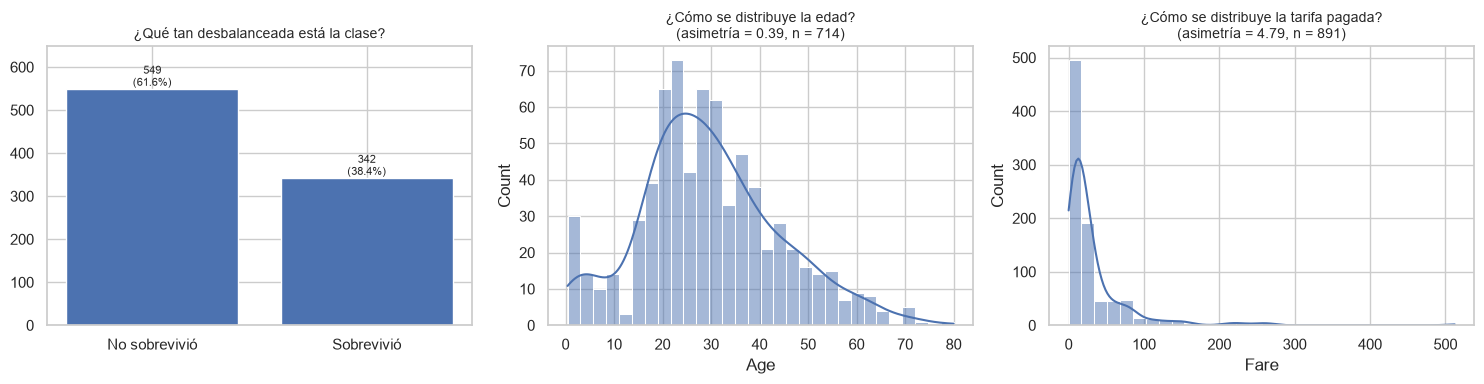

In [11]:
ET = {0: "No sobrevivió", 1: "Sobrevivió"}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
barras(ax[0], titanic["Survived"].map(ET).value_counts(), "¿Qué tan desbalanceada está la clase?")
hist_kde(ax[1], titanic["Age"], "¿Cómo se distribuye la edad?")
hist_kde(ax[2], titanic["Fare"], "¿Cómo se distribuye la tarifa pagada?")
plt.tight_layout(); guardar(fig, "titanic_1_distribuciones"); plt.show()

**Interpretación.** La clase está desbalanceada de forma moderada (61.6 % no sobrevivió, 38.4 % sobrevivió; IR = 1.61). La edad es
aproximadamente simétrica con un grupo de niños pequeños a la izquierda; la tarifa tiene una cola derecha extrema
(asimetría 4.79), con la mayoría de pasajeros pagando menos de 50 y unos pocos más de 500.

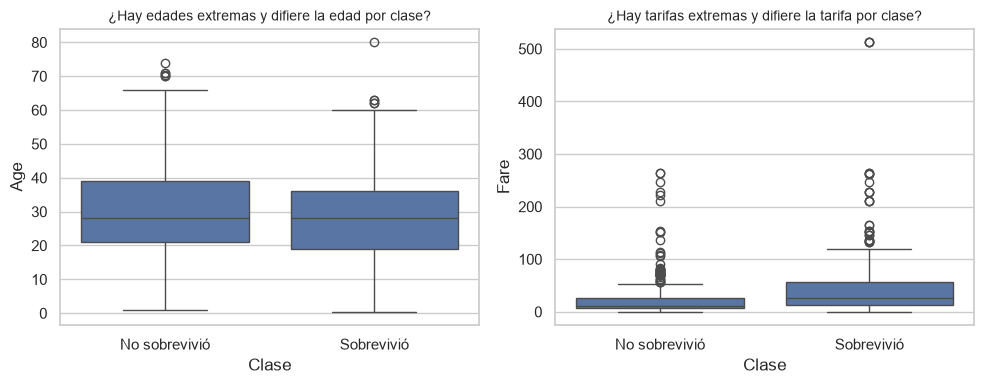

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
caja_por_clase(ax[0], titanic, "Age", "Survived", ET, "¿Hay edades extremas y difiere la edad por clase?")
caja_por_clase(ax[1], titanic, "Fare", "Survived", ET, "¿Hay tarifas extremas y difiere la tarifa por clase?")
plt.tight_layout(); guardar(fig, "titanic_2_boxplots"); plt.show()

**Interpretación.** En `Age` hay pocos valores extremos (solo 8 pasajeros mayores de 65) y las edades medias de ambas clases son parecidas (30.6 y 28.3 años); en `Fare` hay
muchos puntos por encima del bigote superior (53 pasajeros pagaron más de 100), con un máximo de 512. Los sobrevivientes pagaron una tarifa media de 48.4 frente a 22.1 de quienes no sobrevivieron,
lo que anticipa la relación entre clase y supervivencia.

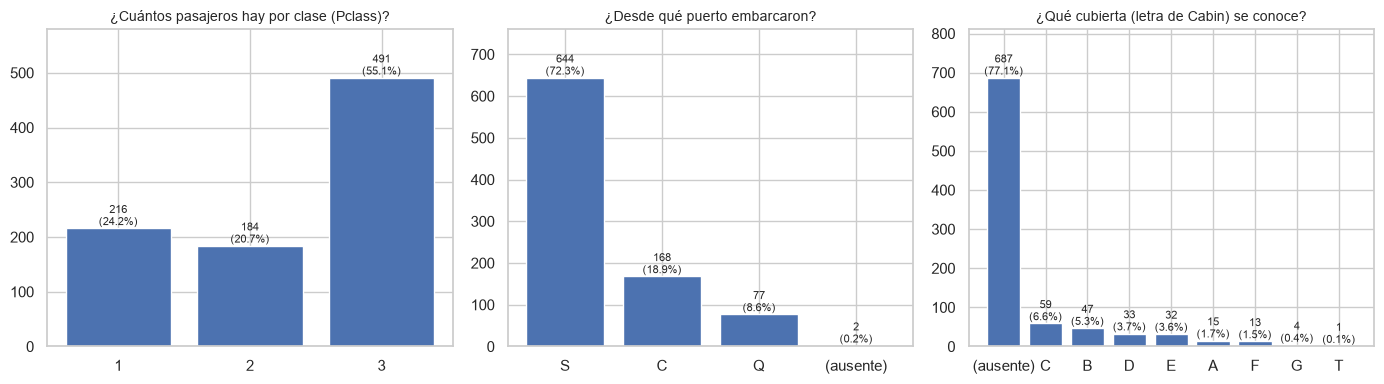

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
barras(ax[0], titanic["Pclass"].value_counts().sort_index(), "¿Cuántos pasajeros hay por clase (Pclass)?")
barras(ax[1], titanic["Embarked"].fillna("(ausente)").value_counts(), "¿Desde qué puerto embarcaron?")
barras(ax[2], titanic["Cabin"].str[0].fillna("(ausente)").value_counts(), "¿Qué cubierta (letra de Cabin) se conoce?")
plt.tight_layout(); guardar(fig, "titanic_3_categoricas"); plt.show()

**Interpretación.** La tercera clase es el 55 % de los pasajeros, el puerto S concentra el 72 % de los embarques (más 2 faltantes) y de
`Cabin` solo se conoce la cubierta en 23 % de los casos: esos faltantes son una característica de los datos, no un descuido aleatorio.

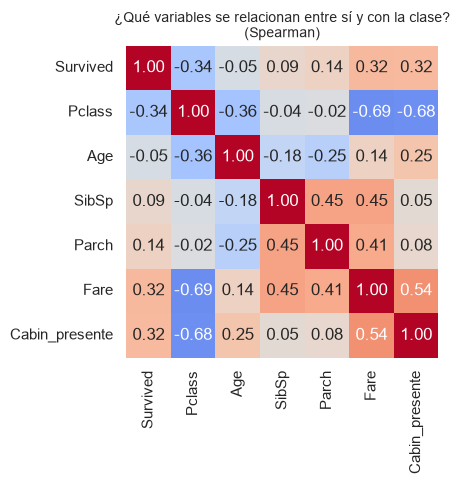

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
t_corr = titanic.assign(Pclass=titanic["Pclass"])
matriz_corr(ax, t_corr, ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "Cabin_presente"],
            "¿Qué variables se relacionan entre sí y con la clase?\n(Spearman)")
plt.tight_layout(); guardar(fig, "titanic_4_correlacion"); plt.show()

**Interpretación.** Las correlaciones con la supervivencia son moderadas: -0.34 con `Pclass` (a mejor clase, más supervivencia), +0.32 con `Fare` y +0.32 con `Cabin_presente`, y casi nula con `Age`
(-0.05, porque su efecto no es lineal, como se ve en la gráfica 5). `Pclass` y `Fare` están correlacionadas entre sí (-0.69), por lo que aportan información parcialmente repetida.
Se usa Spearman porque varias variables son muy asimétricas y ordinales.

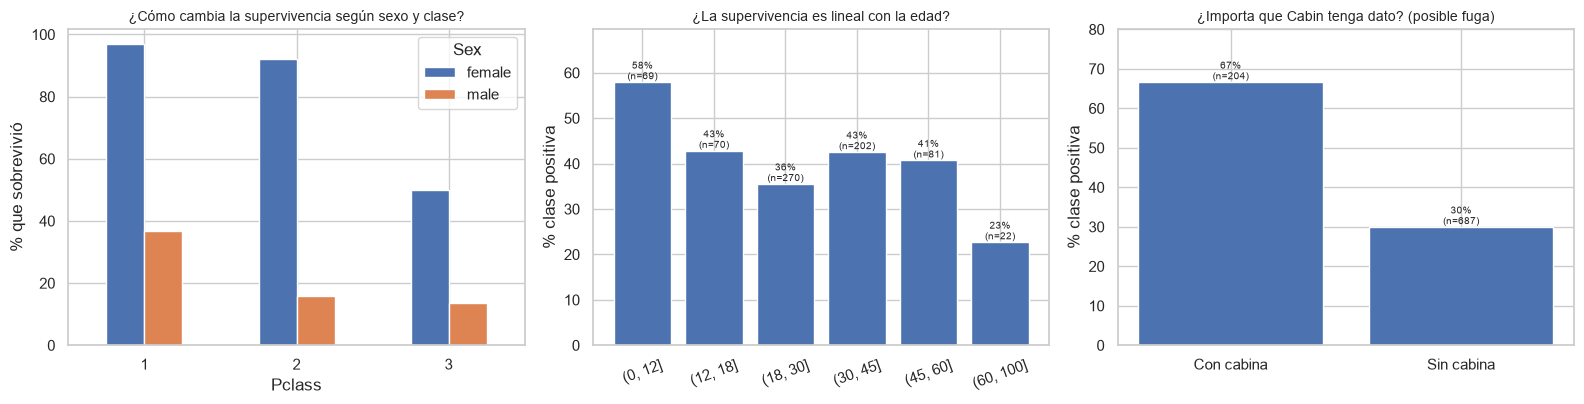

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
pt = titanic.pivot_table(index="Pclass", columns="Sex", values="Survived", aggfunc="mean") * 100
pt.plot(kind="bar", ax=ax[0], rot=0)
ax[0].set_title("¿Cómo cambia la supervivencia según sexo y clase?", fontsize=10)
ax[0].set_ylabel("% que sobrevivió")
tasa_por(ax[1], titanic, "Age", "Survived", "¿La supervivencia es lineal con la edad?",
         bins=[0, 12, 18, 30, 45, 60, 100], rot=20)
tasa_por(ax[2], titanic.assign(Cabin_presente=titanic["Cabin_presente"].map({0: "Sin cabina", 1: "Con cabina"})),
         "Cabin_presente", "Survived", "¿Importa que Cabin tenga dato? (posible fuga)")
plt.tight_layout(); guardar(fig, "titanic_5_relaciones"); plt.show()

**Interpretación.** La relación más fuerte es sexo × clase: sobrevivió cerca del 97 % de las mujeres de primera clase y el 50 % de las de tercera, frente a un 37 % de los hombres
de primera y un 13 % de los de tercera. La relación con la edad **no es lineal**: los menores de 12 años sobreviven 58 %, la supervivencia
baja a 36 % en 18-30 y vuelve a subir a 43 % en 30-45 antes de caer a 23 % después de los 60. Tener cabina registrada se asocia con 67 % de
supervivencia frente a 30 % (posible fuga, ver sección 1).

### 3.2 Adult

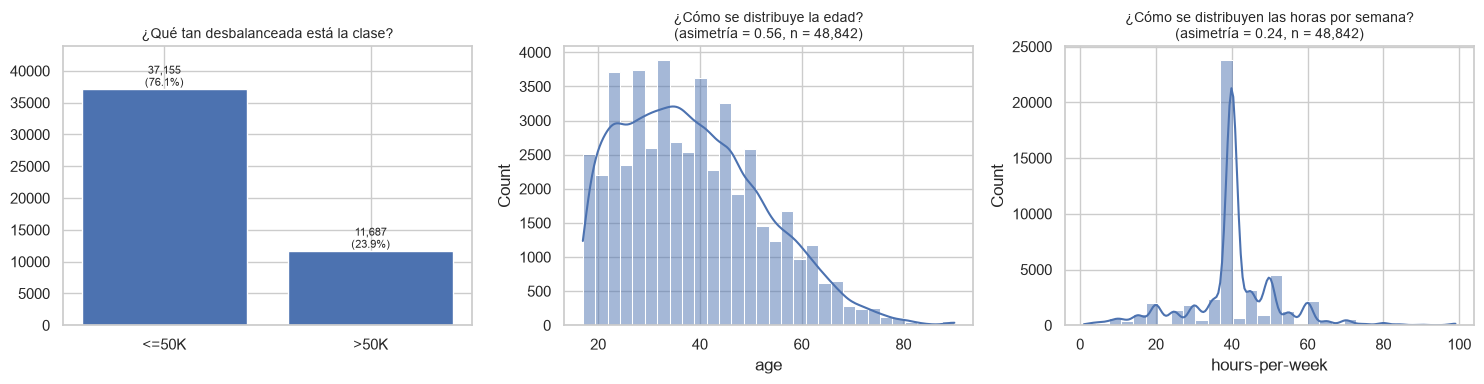

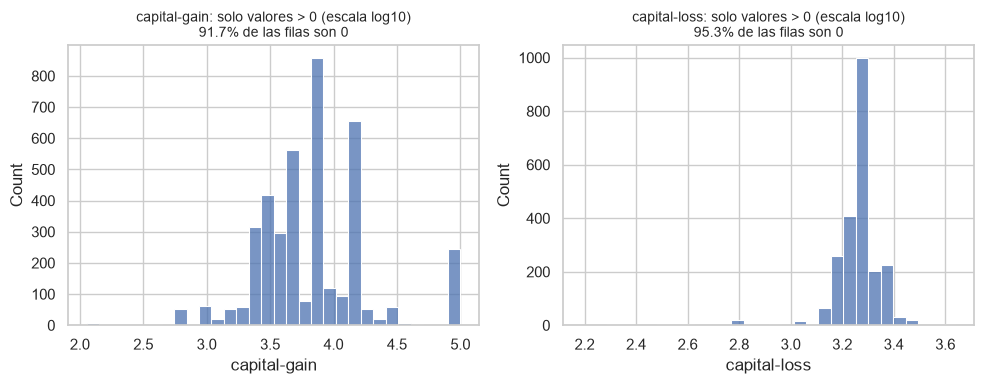

In [16]:
EA = {0: "<=50K", 1: ">50K"}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
barras(ax[0], adult["income_bin"].map(EA).value_counts(), "¿Qué tan desbalanceada está la clase?")
hist_kde(ax[1], adult["age"], "¿Cómo se distribuye la edad?")
hist_kde(ax[2], adult["hours-per-week"], "¿Cómo se distribuyen las horas por semana?")
plt.tight_layout(); guardar(fig, "adult_1_distribuciones"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a_, c in zip(ax, ["capital-gain", "capital-loss"]):
    nz = adult.loc[adult[c] > 0, c]
    sns.histplot(np.log10(nz), bins=30, ax=a_)
    a_.set_title(f"{c}: solo valores > 0 (escala log10)\n{100*(adult[c]==0).mean():.1f}% de las filas son 0", fontsize=10)
plt.tight_layout(); guardar(fig, "adult_1b_capital"); plt.show()

**Interpretación.** La clase `>50K` es el 23.9 % (IR = 3.18), un desbalance claro. La edad tiene una cola derecha moderada y las horas por semana se concentran
fuertemente en 40. `capital-gain` y `capital-loss` son cero para la gran mayoría; los valores positivos están muy dispersos (de cientos a casi 100,000), lo que
hace que su media sea poco representativa.

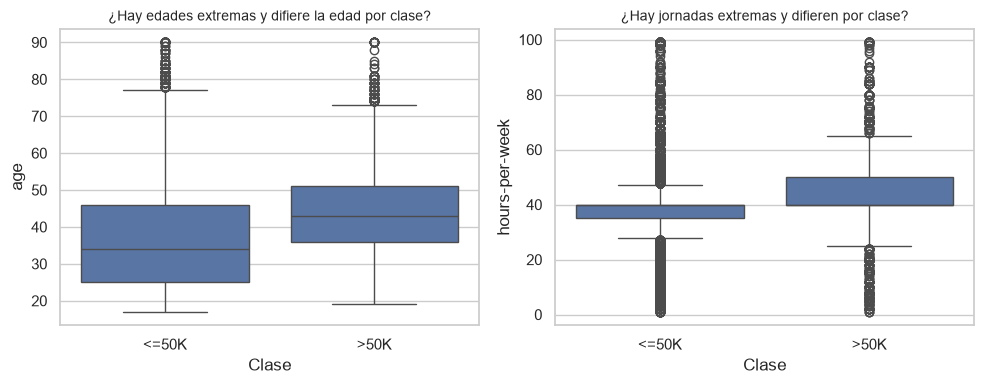

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
caja_por_clase(ax[0], adult, "age", "income_bin", EA, "¿Hay edades extremas y difiere la edad por clase?")
caja_por_clase(ax[1], adult, "hours-per-week", "income_bin", EA, "¿Hay jornadas extremas y difieren por clase?")
plt.tight_layout(); guardar(fig, "adult_2_boxplots"); plt.show()

**Interpretación.** Quienes ganan más de 50K son en promedio mayores y trabajan más horas. En `hours-per-week` el boxplot marca muchos valores como atípicos porque
el rango intercuartílico es muy estrecho (la mitad de la gente trabaja entre 40 y 45 horas): un valor "atípico" por regla estadística no es necesariamente un error.

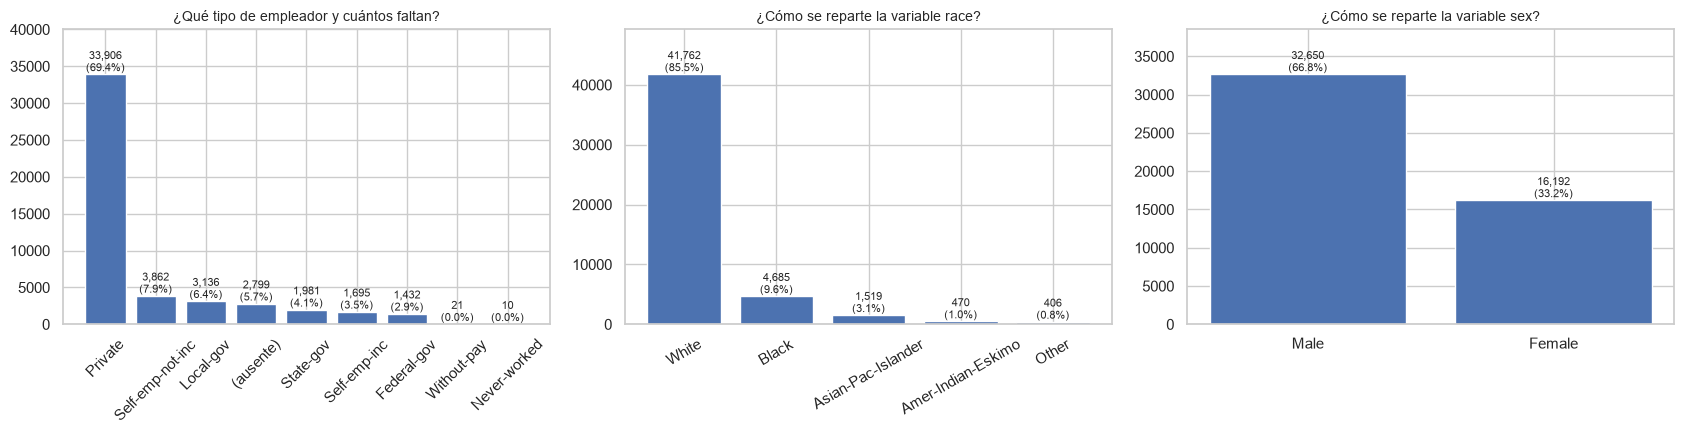

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
barras(ax[0], adult["workclass"].fillna("(ausente)").value_counts(), "¿Qué tipo de empleador y cuántos faltan?", rot=45)
barras(ax[1], adult["race"].value_counts(), "¿Cómo se reparte la variable race?", rot=30)
barras(ax[2], adult["sex"].value_counts(), "¿Cómo se reparte la variable sex?")
plt.tight_layout(); guardar(fig, "adult_3_categoricas"); plt.show()

**Interpretación.** El 69 % trabaja en el sector privado y faltan 5.7 % de los registros. `race` está dominada por una categoría (85.5 % White) y `sex` tiene 67 % de hombres,
una muestra poco equilibrada que conviene tener presente al evaluar sesgos.

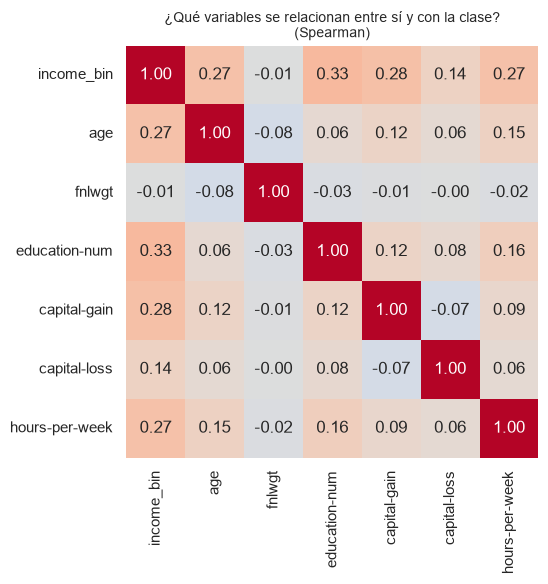

In [19]:
fig, ax = plt.subplots(1, 1, figsize=(7, 6))
matriz_corr(ax, adult, ["income_bin", "age", "fnlwgt", "education-num", "capital-gain", "capital-loss", "hours-per-week"],
            "¿Qué variables se relacionan entre sí y con la clase?\n(Spearman)")
plt.tight_layout(); guardar(fig, "adult_4_correlacion"); plt.show()

**Interpretación.** Las correlaciones entre variables son bajas (la mayor es 0.16 entre numéricas); `education-num`, `age`, `hours-per-week` y `capital-gain` se relacionan
positivamente con ganar más de 50K. `fnlwgt` casi no se relaciona con nada.

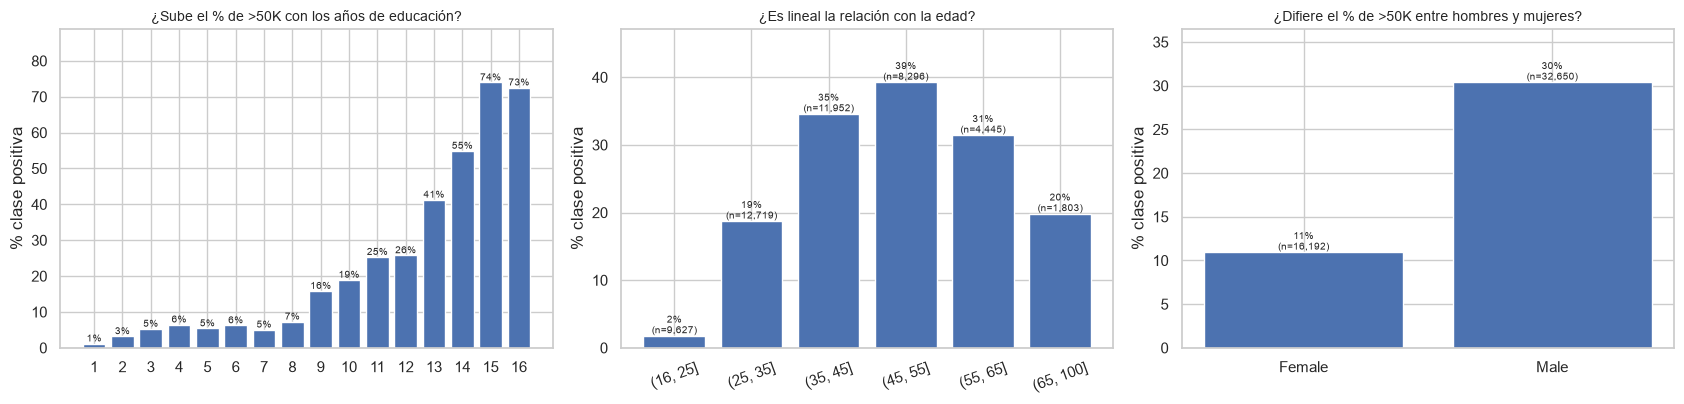

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
tasa_por(ax[0], adult, "education-num", "income_bin", "¿Sube el % de >50K con los años de educación?")
tasa_por(ax[1], adult, "age", "income_bin", "¿Es lineal la relación con la edad?",
         bins=[16, 25, 35, 45, 55, 65, 100], rot=20)
tasa_por(ax[2], adult, "sex", "income_bin", "¿Difiere el % de >50K entre hombres y mujeres?")
plt.tight_layout(); guardar(fig, "adult_5_relaciones"); plt.show()

**Interpretación.** El porcentaje de `>50K` sube de forma no lineal con la educación: se mantiene por debajo de 8 % hasta los 8 años de educación, sube a 16 % con 9 y se dispara a partir de 13 (41 %, 55 %, 74 % y 73 % en los años 13 a 16). La edad muestra una
curva en U invertida (2 % hasta 25 años, máximo de 39 % entre 45 y 55, y 20 % después de 65), por lo que un modelo lineal en `age` es solo una aproximación. Hay una brecha marcada por sexo
(10.9 % de mujeres frente a 30.4 % de hombres), que el modelo puede aprender y reproducir.

## 4. Separación train/test

Se separa **antes** de imputar, winsorizar o balancear. Toda estadística de preprocesamiento se aprende con train y se aplica a test.
Se separan los atributos (`X`) de la clase (`y`) y se construyen las columnas que usará el modelo:

- **Titanic:** se usan `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked` y `Deck` (letra de `Cabin`). Se excluyen `PassengerId`, `Name` y `Ticket` (identificadores). `Pclass` se trata como categoría.
- **Adult:** se excluyen `fnlwgt` (peso muestral) y `education` (redundante con `education-num`). Se conservan `sex` y `race` para poder medir el efecto sobre cada grupo (sección 7); incluirlas en un modelo real requeriría una justificación ética y legal.

In [21]:
def construir_xy_titanic(df):
    X = df[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]].copy()
    X["Pclass"] = X["Pclass"].astype(str)          # clase ordinal tratada como categoría
    X["Deck"] = df["Cabin"].str[0]                 # letra de cubierta; NaN si no hay cabina
    return X, df["Survived"].astype(int)

def construir_xy_adult(df):
    # se excluyen fnlwgt (peso muestral, no es atributo de la persona) y education (redundante con education-num)
    X = df.drop(columns=["income", "income_bin", "fnlwgt", "education"]).copy()
    return X, df["income_bin"]

D = {}
for nombre, (X, y) in {"Titanic": construir_xy_titanic(titanic_raw),
                       "Adult": construir_xy_adult(adult)}.items():
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
    D[nombre] = dict(Xtr=Xtr, Xte=Xte, ytr=ytr, yte=yte)

D["Titanic"].update(num=["Age", "SibSp", "Parch", "Fare"],
                    cat=["Pclass", "Sex", "Embarked", "Deck"],
                    num_imp=["Age"], cat_imp=["Embarked", "Deck"],
                    winsor=["Age", "Fare"], grupo="Sex")
D["Adult"].update(num=["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"],
                  cat=["workclass", "marital-status", "occupation", "relationship", "race", "sex", "native-country"],
                  num_imp=[], cat_imp=["workclass", "occupation", "native-country"],
                  winsor=["age", "capital-gain", "capital-loss", "hours-per-week"], grupo="sex")

resumen_split = pd.DataFrame({
    n: {"filas train": len(d["Xtr"]), "filas test": len(d["Xte"]),
        "% positiva train": 100 * d["ytr"].mean(), "% positiva test": 100 * d["yte"].mean(),
        "ausentes en train": int(d["Xtr"].isna().sum().sum())}
    for n, d in D.items()})
display(resumen_split)

,Titanic,Adult
filas train,668.000,"36,631.000"
filas test,223.000,"12,211.000"
% positiva train,38.323,23.928
% positiva test,38.565,23.929
ausentes en train,655.000,"4,828.000"


In [22]:
def construir_pipeline(num, cat, class_weight=None):
    pre = ColumnTransformer([("num", StandardScaler(), num),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), cat)],
                            sparse_threshold=0)
    clf = LogisticRegression(max_iter=3000, class_weight=class_weight, random_state=SEED)
    return Pipeline([("pre", pre), ("clf", clf)])

def metricas(y_true, y_pred, y_prob):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "roc_auc": roc_auc_score(y_true, y_prob)}

def entrenar_evaluar(Xtr, ytr, Xte, yte, num, cat, class_weight=None):
    m = construir_pipeline(num, cat, class_weight).fit(Xtr[num + cat], ytr)
    pred = m.predict(Xte[num + cat])
    prob = m.predict_proba(Xte[num + cat])[:, 1]
    return metricas(yte, pred, prob)

## 5. Imputación de valores perdidos

**Qué se compara** (todas las estadísticas se calculan solo con train):

| Estrategia | Variable numérica | Variable categórica |
|---|---|---|
| A | Media | Moda |
| B | Mediana | Categoría "Desconocido" |
| C (opcional) | KNN Imputer (5 vecinos, sobre variables estandarizadas) | Moda |
| B + indicador | Igual que B, más una columna binaria `<variable>_ausente` | Igual que B, más indicador |

- **Variable numérica:** `Age` (Titanic). Adult no tiene faltantes numéricos, por lo que su imputación numérica no aplica.
- **Variables categóricas:** `Embarked` y `Deck` (Titanic) y `workclass`, `occupation` y `native-country` (Adult).
- Los indicadores de ausencia se crean para las variables que realmente tienen faltantes (el enunciado los pide cuando la ausencia puede ser informativa).

In [23]:
def imputar(Xtr, Xte, estrategia, num_imp, cat_imp, indicadores=False, knn_cols=None):
    # Todas las estadísticas (media, mediana, moda, vecinos) se calculan SOLO con train
    tr, te = Xtr.copy(), Xte.copy()
    extra = []
    if indicadores:                          # bandera binaria "el valor estaba ausente"
        for c in num_imp + cat_imp:
            if Xtr[c].isna().any():
                tr[c + "_ausente"] = Xtr[c].isna().astype(int)
                te[c + "_ausente"] = Xte[c].isna().astype(int)
                extra.append(c + "_ausente")
    if estrategia in ("A", "B"):
        for c in num_imp:
            v = Xtr[c].mean() if estrategia == "A" else Xtr[c].median()
            tr[c] = tr[c].fillna(v); te[c] = te[c].fillna(v)
    if estrategia == "C" and num_imp:        # KNN sobre variables numéricas estandarizadas
        esc = StandardScaler().fit(tr[knn_cols])
        knn = KNNImputer(n_neighbors=5).fit(esc.transform(tr[knn_cols]))
        tr[knn_cols] = esc.inverse_transform(knn.transform(esc.transform(tr[knn_cols])))
        te[knn_cols] = esc.inverse_transform(knn.transform(esc.transform(te[knn_cols])))
    for c in cat_imp:
        v = "Desconocido" if estrategia == "B" else Xtr[c].mode().iloc[0]
        tr[c] = tr[c].fillna(v); te[c] = te[c].fillna(v)
    return tr, te, extra

ESTRATEGIAS = {
    "A: media / moda":              dict(estrategia="A", indicadores=False),
    "B: mediana / 'Desconocido'":   dict(estrategia="B", indicadores=False),
    "C: KNN / moda":                dict(estrategia="C", indicadores=False),
    "B + indicador de ausencia":    dict(estrategia="B", indicadores=True),
}
KNN_COLS = {"Titanic": ["Age", "SibSp", "Parch", "Fare"], "Adult": None}

def estrategias_de(nombre):
    # En Adult ninguna variable numérica tiene faltantes, por eso no se aplica KNN
    return {k: v for k, v in ESTRATEGIAS.items() if not (nombre == "Adult" and v["estrategia"] == "C")}

IMP = {}   # IMP[dataset][estrategia] = (train imputado, test imputado, columnas extra)
for nombre, d in D.items():
    IMP[nombre] = {}
    for etiqueta, params in estrategias_de(nombre).items():
        tr, te, extra = imputar(d["Xtr"], d["Xte"], num_imp=d["num_imp"], cat_imp=d["cat_imp"],
                                knn_cols=KNN_COLS[nombre], **params)
        assert tr[d["num"] + d["cat"]].isna().sum().sum() == 0 and te[d["num"] + d["cat"]].isna().sum().sum() == 0
        IMP[nombre][etiqueta] = (tr, te, extra)
print("Imputación lista; no quedan ausentes en ninguna estrategia.")

Imputación lista; no quedan ausentes en ninguna estrategia.


### 5.1 ¿Cambia la distribución y la varianza? (variable numérica `Age`)

,n,media,mediana,desv.est,varianza,asimetria,% en el valor mas repetido,valor mas repetido
Original (solo observados),537.000,29.932,29.000,14.456,208.975,0.351,4.655,22.000
A: media / moda,668.000,29.932,29.932,12.959,167.932,0.391,19.611,29.930
B: mediana / 'Desconocido',668.000,29.749,29.000,12.964,168.069,0.433,22.006,29.000
C: KNN / moda,668.000,30.075,29.300,13.616,185.401,0.306,3.743,22.000


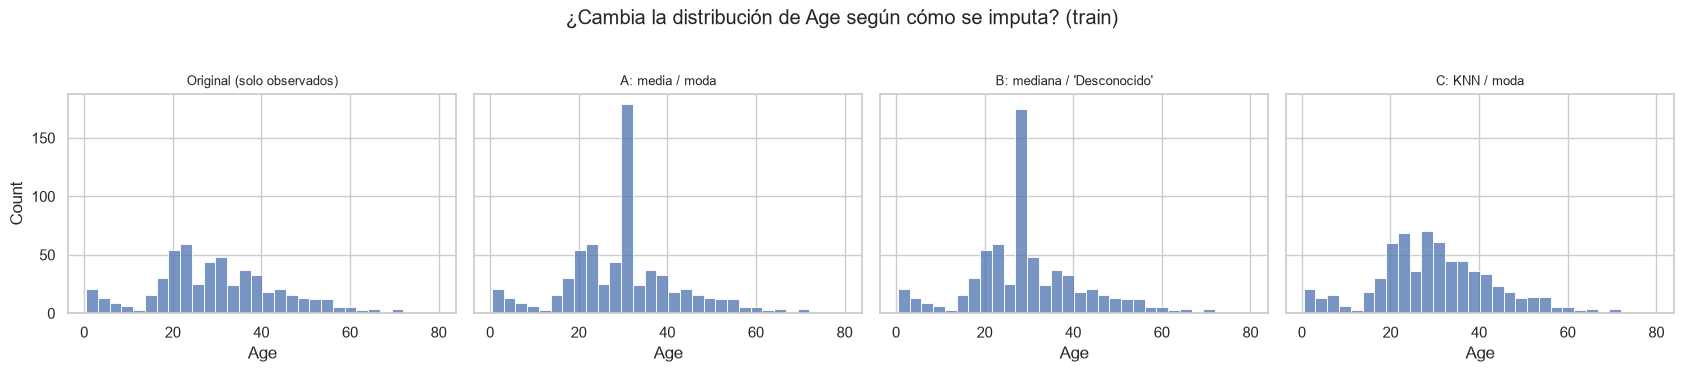

In [24]:
# --- Variable numérica: Age (Titanic) ---
d = D["Titanic"]
orig = d["Xtr"]["Age"].dropna()
series = {"Original (solo observados)": orig}
for etiqueta in ["A: media / moda", "B: mediana / 'Desconocido'", "C: KNN / moda"]:
    series[etiqueta] = IMP["Titanic"][etiqueta][0]["Age"]

def resumen_dist(s):
    vc = s.round(2).value_counts(normalize=True)
    return {"n": len(s), "media": s.mean(), "mediana": s.median(), "desv.est": s.std(),
            "varianza": s.var(), "asimetria": s.skew(),
            "% en el valor mas repetido": 100 * vc.iloc[0], "valor mas repetido": vc.index[0]}

tabla_age = pd.DataFrame({k: resumen_dist(v) for k, v in series.items()}).T
display(tabla_age)
guardar_tabla(tabla_age, "imputacion_titanic_age_distribucion")

fig, ax = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True, sharex=True)
for a_, (k, s) in zip(ax, series.items()):
    sns.histplot(s, bins=30, ax=a_)
    a_.set_title(k, fontsize=9)
fig.suptitle("¿Cambia la distribución de Age según cómo se imputa? (train)", y=1.03)
plt.tight_layout(); guardar(fig, "titanic_imputacion_age"); plt.show()

**Interpretación.** Las estrategias A y B comprimen la distribución: la varianza baja de 209 (solo observados) a 168 (-20 %) y aparece una **concentración artificial**: cerca del 20-22 % de las edades de train pasan a valer exactamente
29.9 (A) o 29.0 (B), cuando el valor más repetido en los datos reales solo representa el 4.7 %. KNN conserva mejor la forma (varianza 186; valor más repetido en 3.7 %) porque imputa según pasajeros parecidos
(`SibSp`, `Parch` y `Fare`), pero sigue siendo una estimación. Media y mediana difieren poco porque `Age` es casi simétrica; en una variable muy asimétrica la mediana sería mucho más robusta.

### 5.2 ¿Se crean concentraciones artificiales en las categóricas?


Titanic - Deck (% de filas de train)


,Original (con ausentes),A: media / moda,B: mediana / 'Desconocido'
Deck,,,
C,5.689,83.832,5.689
(ausente),78.144,0.000,0.000
B,4.790,4.790,4.790
E,3.743,3.743,3.743
D,3.593,3.593,3.593
A,1.946,1.946,1.946
F,1.497,1.497,1.497
G,0.449,0.449,0.449



Titanic - Embarked (% de filas de train)


,Original (con ausentes),A: media / moda,B: mediana / 'Desconocido'
Embarked,,,
S,71.707,72.006,71.707
C,19.910,19.910,19.910
Q,8.084,8.084,8.084
(ausente),0.299,0.000,0.000



Adult - workclass (% de filas de train)


,Original (con ausentes),A: media / moda,B: mediana / 'Desconocido'
workclass,,,
Private,69.406,75.100,69.406
Self-emp-not-inc,7.892,7.892,7.892
Local-gov,6.530,6.530,6.530
(ausente),5.695,0.000,0.000
State-gov,3.947,3.947,3.947
Self-emp-inc,3.505,3.505,3.505
Federal-gov,2.954,2.954,2.954
Without-pay,0.049,0.049,0.049



Adult - occupation (% de filas de train)


,Original (con ausentes),A: media / moda,B: mediana / 'Desconocido'
occupation,,,
Exec-managerial,12.596,18.312,12.596
Prof-specialty,12.569,12.569,12.569
Craft-repair,12.416,12.416,12.416
Adm-clerical,11.460,11.460,11.460
Sales,11.291,11.291,11.291
Other-service,10.032,10.032,10.032
Machine-op-inspct,6.265,6.265,6.265
(ausente),5.716,0.000,0.000



Adult - native-country (% de filas de train)


,Original (con ausentes),A: media / moda,B: mediana / 'Desconocido'
native-country,,,
United-States,89.648,91.417,89.648
Mexico,2.020,2.020,2.020
(ausente),1.769,0.000,0.000
Philippines,0.606,0.606,0.606
Germany,0.415,0.415,0.415
Puerto-Rico,0.369,0.369,0.369
Canada,0.366,0.366,0.366
El-Salvador,0.328,0.328,0.328


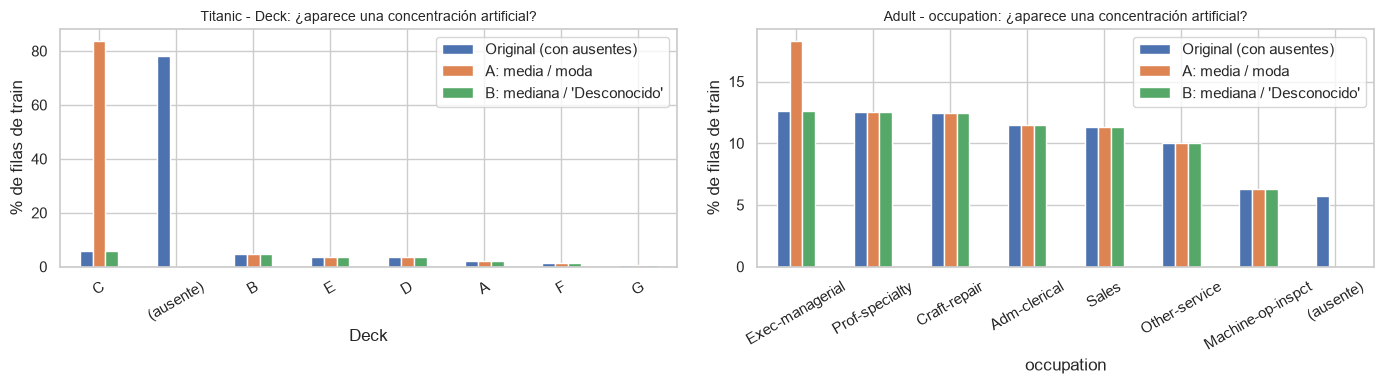

In [25]:
# --- Variables categóricas: distribución antes y después (train) ---
def comparar_categorica(nombre, col):
    d = D[nombre]
    antes = d["Xtr"][col].fillna("(ausente)").value_counts(normalize=True) * 100
    tabla = pd.DataFrame({"Original (con ausentes)": antes})
    for et in ["A: media / moda", "B: mediana / 'Desconocido'"]:
        tabla[et] = IMP[nombre][et][0][col].value_counts(normalize=True) * 100
    tabla = tabla.fillna(0)
    return tabla.loc[tabla.max(axis=1).sort_values(ascending=False).index]

for nombre, col in [("Titanic", "Deck"), ("Titanic", "Embarked"), ("Adult", "workclass"),
                    ("Adult", "occupation"), ("Adult", "native-country")]:
    t = comparar_categorica(nombre, col)
    print(f"\n{nombre} - {col} (% de filas de train)")
    display(t.head(8))
    guardar_tabla(t, f"imputacion_{nombre.lower()}_{col}_frecuencias")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a_, (nombre, col) in zip(ax, [("Titanic", "Deck"), ("Adult", "occupation")]):
    comparar_categorica(nombre, col).head(8).plot(kind="bar", ax=a_, rot=30)
    a_.set_title(f"{nombre} - {col}: ¿aparece una concentración artificial?", fontsize=10)
    a_.set_ylabel("% de filas de train")
plt.tight_layout(); guardar(fig, "imputacion_categoricas"); plt.show()

**Interpretación.** Imputar con la **moda** distorsiona seriamente las categóricas cuando falta mucho. En `Deck`, el 78 % de train no tiene cubierta; la moda (`C`) pasa de 5.7 % a 83.8 %, y el modelo recibiría 'cubierta C' para pasajeros
sin cabina registrada (el 70 % de ellos son de tercera clase). En Adult el efecto es menor porque faltan 5-6 %, pero igualmente infla `Private` de 69.4 % a 75.1 % y `Exec-managerial` de 12.6 % a 18.3 %.
Con la categoría **"Desconocido"** las frecuencias de las categorías reales no cambian y la ausencia se vuelve una categoría explícita. En `Embarked`, que solo tiene 2 faltantes, ambas estrategias son equivalentes.

### 5.3 ¿Cambia el desempeño del clasificador?

In [26]:
# --- Impacto en el desempeño del clasificador (mismo modelo, mismo test) ---
filas = []
for nombre, d in D.items():
    for etiqueta, (tr, te, extra) in IMP[nombre].items():
        m = entrenar_evaluar(tr, d["ytr"], te, d["yte"], d["num"] + extra, d["cat"])
        filas.append({"dataset": nombre, "estrategia": etiqueta, **m})
res_imp = pd.DataFrame(filas).set_index(["dataset", "estrategia"])
display(res_imp)
guardar_tabla(res_imp, "imputacion_desempeno")

accuracy  precision  recall    f1  balanced_acc  roc_auc
dataset estrategia                                                                          
Titanic A: media / moda                0.789      0.747   0.686 0.715         0.770    0.840
        B: mediana / 'Desconocido'     0.785      0.738   0.686 0.711         0.766    0.838
        C: KNN / moda                  0.789      0.747   0.686 0.715         0.770    0.840
        B + indicador de ausencia      0.789      0.747   0.686 0.715         0.770    0.834
Adult   A: media / moda                0.849      0.727   0.593 0.653         0.761    0.902
        B: mediana / 'Desconocido'     0.852      0.733   0.601 0.660         0.766    0.904
        B + indicador de ausencia      0.852      0.733   0.601 0.661         0.766    0.904

Con un solo test (223 pasajeros en Titanic), una sola predicción distinta mueve la accuracy 0.45 puntos, así que estas diferencias son ruido. La sección 8 repite el experimento con 10 particiones; de ahí sale la conclusión.

**Interpretación .** En 10 particiones, el F1 de Titanic es 0.724 (A), 0.724 (B), 0.720 (KNN) y 0.723 (B + indicador), con desviaciones de ~0.025: **no hay diferencia detectable**. En Adult, A obtiene F1 = 0.654 y B y B + indicador 0.657
(desviación ~0.008): una diferencia mínima a favor de "Desconocido". Es decir, la imputación no cambia el desempeño de un modelo lineal, así que la decisión debe basarse en la **integridad de los datos** (no inventar valores ni crear concentraciones artificiales), no en la métrica.

### 5.4 Decisión de imputación

**Estrategia elegida: B + indicador de ausencia** (mediana para numéricas, "Desconocido" para categóricas y una columna binaria `_ausente` por variable con faltantes).

Justificación:
1. No distorsiona las frecuencias de las categorías (la moda convertiría el 78 % de `Deck` en la cubierta C).
2. La mediana es robusta ante la asimetría y ante valores extremos.
3. La ausencia puede ser informativa (en Titanic, tener cabina se asocia con mucha mayor supervivencia; en Adult, `workclass` y `occupation` faltan juntos); el indicador conserva esa información.
4. El desempeño es equivalente al de las otras estrategias, por lo que no se pierde nada.

Limitación: la mediana sigue concentrando valores (22 % de `Age` en 29.0); KNN preserva mejor la distribución de `Age` y sería una alternativa si la distribución fuese lo más importante. Además, el indicador `Deck_ausente` repite
la información de la categoría "Desconocido" (son redundantes); la regularización de la regresión logística lo tolera.

In [27]:
FINAL_IMP = "B + indicador de ausencia"     # decisión final (justificada arriba)
for nombre, d in D.items():
    tr, te, extra = IMP[nombre][FINAL_IMP]
    d["tr_imp"], d["te_imp"], d["num_final"] = tr, te, d["num"] + extra
    print(f"{nombre}: columnas numéricas del modelo = {d['num_final']}")

Titanic: columnas numéricas del modelo = ['Age', 'SibSp', 'Parch', 'Fare', 'Age_ausente', 'Embarked_ausente', 'Deck_ausente']
Adult: columnas numéricas del modelo = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week', 'workclass_ausente', 'occupation_ausente', 'native-country_ausente']


## 6. Detección y tratamiento de outliers (winsorización)

Winsorizar es **recortar** los valores extremos a un límite en lugar de eliminar filas. Se comparan dos criterios, siempre con límites calculados en train y aplicados a train y test:

- **Rango intercuartílico (IQR):** límites `Q1 - 1.5·IQR` y `Q3 + 1.5·IQR` (k = 1.5, convención de Tukey).
- **Percentiles extremos:** límites en los percentiles 1 y 99.

Primero se calcula cuántos datos recortaría cada criterio en **todas** las numéricas, para decidir cuáles winsorizar.

In [28]:
def limites(s, criterio):
    if criterio == "IQR":
        q1, q3 = s.quantile(.25), s.quantile(.75)
        iqr = q3 - q1
        return q1 - K_IQR * iqr, q3 + K_IQR * iqr
    return s.quantile(PCT_INF / 100), s.quantile(PCT_SUP / 100)

def winsorizar(tr, te, cols, criterio):
    # límites calculados con train y aplicados (clip) a train y test
    tr, te = tr.copy(), te.copy()
    lims = {}
    for c in cols:
        lo, hi = limites(tr[c], criterio)
        lims[c] = (lo, hi)
        tr[c] = tr[c].clip(lo, hi)
        te[c] = te[c].clip(lo, hi)
    return tr, te, lims

def tabla_limites(nombre):
    d = D[nombre]; tr = d["tr_imp"]
    filas = []
    for c in d["num"]:
        for crit in ["IQR", "Percentiles"]:
            lo, hi = limites(tr[c], crit)
            filas.append({"variable": c, "criterio": crit, "limite_inf": lo, "limite_sup": hi,
                          "% recortado": 100 * ((tr[c] < lo) | (tr[c] > hi)).mean(),
                          "min": tr[c].min(), "max": tr[c].max()})
    return pd.DataFrame(filas).set_index(["variable", "criterio"])

for nombre in D:
    print(f"\n{nombre}: límites por criterio (IQR con k = {K_IQR}; percentiles {PCT_INF}-{PCT_SUP})")
    t = tabla_limites(nombre)
    display(t)
    guardar_tabla(t, f"winsor_{nombre.lower()}_limites")


Titanic: límites por criterio (IQR con k = 1.5; percentiles 1-99)


limite_inf  limite_sup  % recortado   min     max
variable criterio                                                      
Age      IQR               1.000      57.000        4.042 0.420  80.000
         Percentiles       1.000      65.330        1.946 0.420  80.000
SibSp    IQR              -1.500       2.500        4.192 0.000   8.000
         Percentiles       0.000       4.000        0.599 0.000   8.000
Parch    IQR               0.000       0.000       22.754 0.000   6.000
         Percentiles       0.000       4.000        0.898 0.000   6.000
Fare     IQR             -26.011      64.406       12.874 0.000 512.329
         Percentiles       0.000     227.525        0.898 0.000 512.329


Adult: límites por criterio (IQR con k = 1.5; percentiles 1-99)


limite_inf  limite_sup  % recortado  min    max
variable       criterio                                                    
age            IQR              -2.000      78.000        0.431   17     90
               Percentiles      17.000      74.000        0.887   17     90
education-num  IQR               4.500      16.500        3.762    1     16
               Percentiles       3.000      16.000        0.715    1     16
capital-gain   IQR               0.000       0.000        8.187    0  99999
               Percentiles       0.000  15,024.000        0.756    0  99999
capital-loss   IQR               0.000       0.000        4.671    0   4356
               Percentiles       0.000   1,980.000        0.988    0   4356
hours-per-week IQR              32.500      52.500       27.646    1     99
               Percentiles       8.000      80.000        1.548    1     99

**Lectura de los límites.**
- Para variables discretas o con muchos ceros, el criterio IQR degenera: en `Parch` el IQR es 0, los límites quedan en [0, 0] y se recortaría el 22.8 % de las filas; en `capital-gain` y `capital-loss`
  (92 % y 95 % de ceros) el IQR también es 0 y **toda** la columna quedaría en 0. En `hours-per-week` el IQR es estrecho (40 a 45) y recortaría el 27.6 % de las filas a [32.5, 52.5], aunque trabajar 30 o 60 horas es perfectamente normal.
- El criterio de percentiles siempre recorta una proporción pequeña y conocida (≈ 1-2 %).

**Variables a winsorizar.** Titanic: `Age` y `Fare`. Adult: `age`, `capital-gain`, `capital-loss` y `hours-per-week`. No se winsorizan `SibSp`, `Parch` ni `education-num` (conteos discretos o escala ordinal con dominio acotado), ni los indicadores binarios.

In [29]:
W = {}   # W[dataset][escenario] = (train, test)
for nombre, d in D.items():
    W[nombre] = {"Sin winsorizar": (d["tr_imp"], d["te_imp"])}
    for crit in ["IQR", "Percentiles"]:
        tr, te, _ = winsorizar(d["tr_imp"], d["te_imp"], d["winsor"], crit)
        W[nombre][crit] = (tr, te)

# Estadísticos antes y después en las columnas winsorizadas
for nombre, d in D.items():
    filas = []
    for c in d["winsor"]:
        for esc, (tr, _) in W[nombre].items():
            s = tr[c]
            filas.append({"variable": c, "escenario": esc, "media": s.mean(), "mediana": s.median(),
                          "desv.est": s.std(), "min": s.min(), "max": s.max(), "asimetria": s.skew()})
    t = pd.DataFrame(filas).set_index(["variable", "escenario"])
    print(f"\n{nombre}: estadísticos en train antes y después de winsorizar")
    display(t)
    guardar_tabla(t, f"winsor_{nombre.lower()}_estadisticos")

# Desempeño del modelo
filas = []
for nombre, d in D.items():
    for esc, (tr, te) in W[nombre].items():
        m = entrenar_evaluar(tr, d["ytr"], te, d["yte"], d["num_final"], d["cat"])
        filas.append({"dataset": nombre, "escenario": esc, **m})
res_win = pd.DataFrame(filas).set_index(["dataset", "escenario"])
display(res_win)
guardar_tabla(res_win, "winsor_desempeno")


Titanic: estadísticos en train antes y después de winsorizar


media  mediana  desv.est   min     max  asimetria
variable escenario                                                        
Age      Sin winsorizar 29.749   29.000    12.964 0.420  80.000      0.433
         IQR            29.507   29.000    12.309 1.000  57.000      0.119
         Percentiles    29.684   29.000    12.748 1.000  65.330      0.315
Fare     Sin winsorizar 31.177   13.860    47.458 0.000 512.329      4.845
         IQR            23.441   13.860    20.043 0.000  64.406      1.100
         Percentiles    30.161   13.860    40.040 0.000 227.525      2.936


Adult: estadísticos en train antes y después de winsorizar


media  mediana  desv.est    min        max  asimetria
variable       escenario                                                               
age            Sin winsorizar    38.652   37.000    13.696 17.000     90.000      0.556
               IQR               38.629   37.000    13.622 17.000     78.000      0.517
               Percentiles       38.601   37.000    13.546 17.000     74.000      0.486
capital-gain   Sin winsorizar 1,039.436    0.000 7,194.360  0.000 99,999.000     12.239
               IQR                0.000    0.000     0.000  0.000      0.000      0.000
               Percentiles      619.064    0.000 2,483.486  0.000 15,024.000      4.623
capital-loss   Sin winsorizar    87.405    0.000   402.654  0.000  4,356.000      4.573
               IQR                0.000    0.000     0.000  0.000      0.000      0.000
               Percentiles       84.010    0.000   383.405  0.000  1,980.000      4.400
hours-per-week Sin winsorizar    40.461   40.000    12.387  1.000     99.000      0.229
               IQR               41.221   40.000     6.195 32.500     52.500      0.434
               Percentiles       40.414   40.000    11.977  8.000     80.000      0.014

accuracy  precision  recall    f1  balanced_acc  roc_auc
dataset escenario                                                               
Titanic Sin winsorizar     0.789      0.747   0.686 0.715         0.770    0.834
        IQR                0.785      0.738   0.686 0.711         0.766    0.838
        Percentiles        0.789      0.747   0.686 0.715         0.770    0.834
Adult   Sin winsorizar     0.852      0.733   0.601 0.661         0.766    0.904
        IQR                0.840      0.707   0.563 0.627         0.745    0.885
        Percentiles        0.852      0.734   0.601 0.661         0.766    0.905

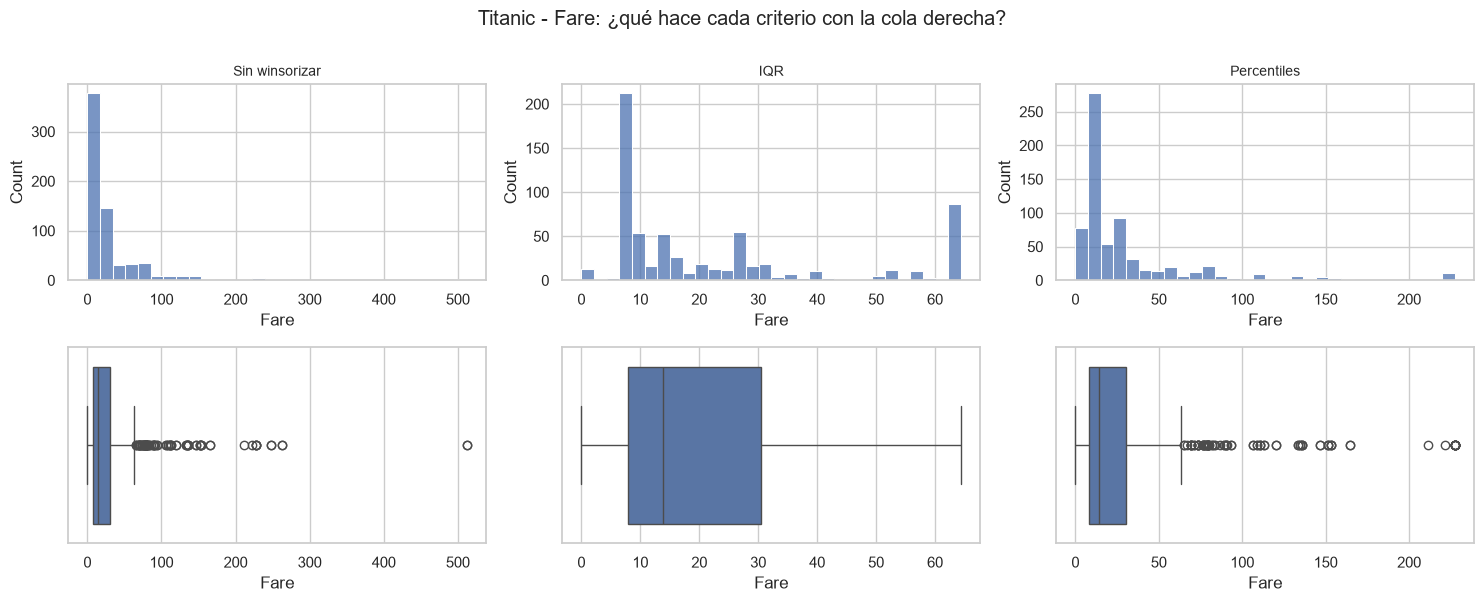

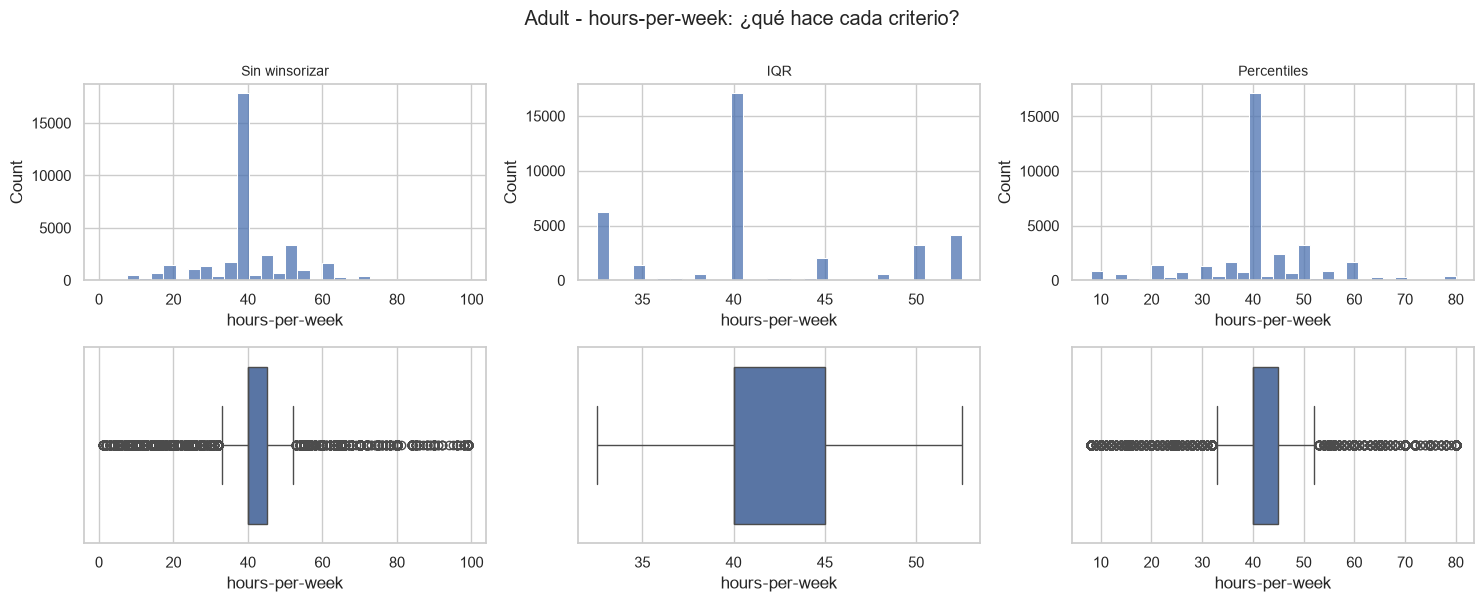

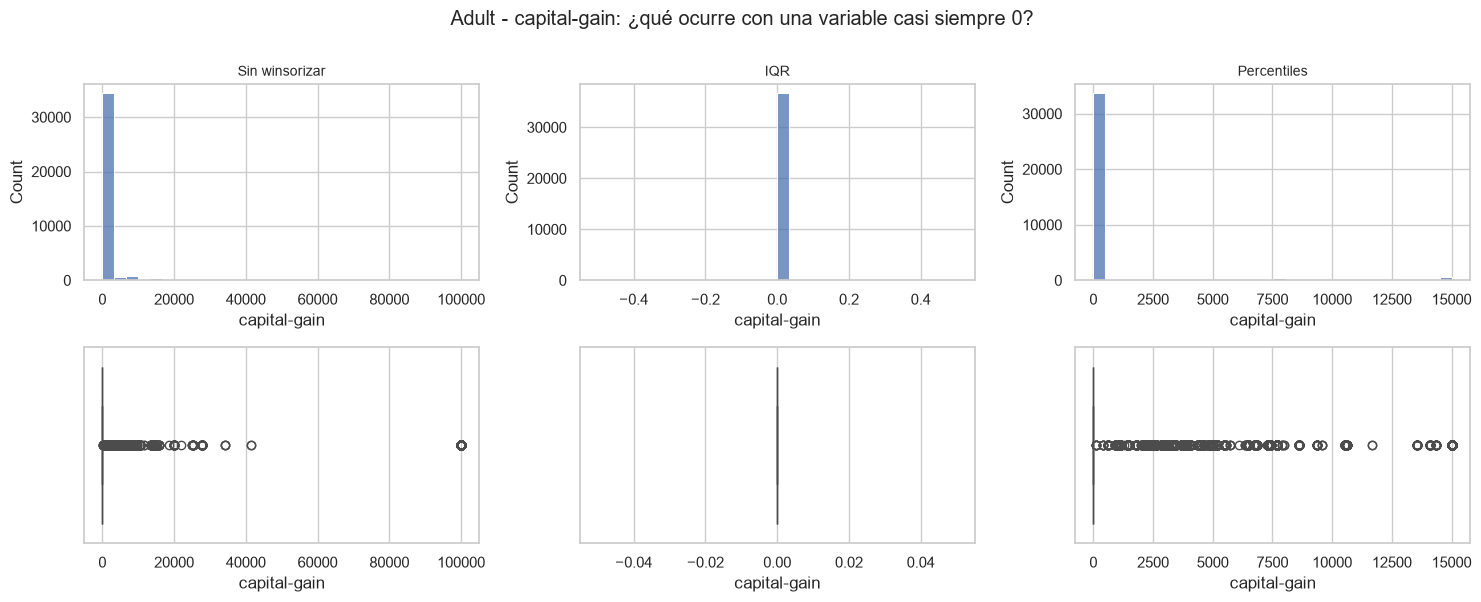

In [30]:
def antes_despues(nombre, col, titulo):
    fig, ax = plt.subplots(2, 3, figsize=(15, 6))
    for j, esc in enumerate(["Sin winsorizar", "IQR", "Percentiles"]):
        s = W[nombre][esc][0][col]
        sns.histplot(s, bins=30, ax=ax[0, j])
        ax[0, j].set_title(f"{esc}", fontsize=10)
        sns.boxplot(x=s, ax=ax[1, j])
    fig.suptitle(titulo, y=1.0)
    plt.tight_layout(); guardar(fig, f"winsor_{nombre.lower()}_{col}"); plt.show()

antes_despues("Titanic", "Fare", "Titanic - Fare: ¿qué hace cada criterio con la cola derecha?")
antes_despues("Adult", "hours-per-week", "Adult - hours-per-week: ¿qué hace cada criterio?")
antes_despues("Adult", "capital-gain", "Adult - capital-gain: ¿qué ocurre con una variable casi siempre 0?")

**Interpretación.**
- **Titanic, `Fare`:** IQR fija el máximo en 64.4 y recorta el 12.9 % de las tarifas (la desviación estándar baja de 47.5 a 20.0 y la media de 31.2 a 23.4). Percentiles lo fija en 227.5 y recorta solo el 0.9 % (desviación 40.0): conserva la
  distinción entre tarifas altas y muy altas. La asimetría baja de 4.8 a 1.1 (IQR) y 2.9 (percentiles).
- **Adult, `capital-gain` y `capital-loss`:** con IQR **todas las filas quedan en 0** (media, desviación y máximo = 0): se destruye la variable. Con percentiles 1-99 el máximo de `capital-gain` baja de 99,999 (valor tope de captura) a 15,024 y la desviación de 7,194 a 2,483.
- **Adult, `hours-per-week`:** IQR recorta más de una cuarta parte de los datos y reduce la desviación a la mitad (12.4 a 6.2); percentiles recorta 1.5 % (a [8, 80]) y la distribución casi no cambia.
- **Desempeño (en 10 particiones, sección 8):** en Adult, F1 = 0.657 sin winsorizar, **0.618 con IQR** y 0.659 con percentiles; el IQR claramente **empeora** el modelo (desviación ~0.006) porque elimina información de `capital-gain` y `capital-loss`. En Titanic: 0.723, 0.717 y 0.726,
  diferencias dentro del ruido. Que percentiles no mejore apreciablemente es esperable: solo modifica entre 1 y 2 % de los valores.

### 6.1 Decisión de winsorización

**Criterio elegido: percentiles 1-99** sobre las variables seleccionadas, con límites calculados en train.

Justificación: (1) recorta una proporción pequeña y controlada; (2) no colapsa variables con muchos ceros, como sí hace el IQR; (3) trata los valores tope (99999 en `capital-gain`) sin eliminar filas; (4) no empeora el desempeño. Los límites son una decisión de criterio:
si se cambiaran a 5-95 se recortaría más información, y a 0.5-99.5 se recortaría menos. Limitación: un recorte simétrico en `age` o en `Age` no tiene justificación de dominio (una persona de 90 años no es un error); se aplicó por consistencia y casi no modifica los datos.

In [31]:
CRITERIO_FINAL = "Percentiles"     # decisión final (justificada arriba)
for nombre, d in D.items():
    d["tr_w"], d["te_w"] = W[nombre][CRITERIO_FINAL]
    print(f"{nombre}: winsorización final = {CRITERIO_FINAL} ({PCT_INF}-{PCT_SUP}) sobre {d['winsor']}")

Titanic: winsorización final = Percentiles (1-99) sobre ['Age', 'Fare']
Adult: winsorización final = Percentiles (1-99) sobre ['age', 'capital-gain', 'capital-loss', 'hours-per-week']


## 7. Tratamiento del desbalance

### 7.1 Diagnóstico

Se calcula la cantidad y porcentaje por clase y la razón de desbalance `IR = N_mayoritaria / N_minoritaria`. Si **IR > 1.5** el dataset se considera desbalanceado.

In [32]:
def tabla_desbalance(y, etiquetas):
    vc = y.value_counts()
    t = pd.DataFrame({"clase": [etiquetas[i] for i in vc.index], "observaciones": vc.values,
                      "%": 100 * vc.values / len(y)}).set_index("clase")
    ir = vc.max() / vc.min()
    return t, ir

ETIQ = {"Titanic": ET, "Adult": EA}
filas = []
for nombre, d in D.items():
    y_total = pd.concat([d["ytr"], d["yte"]])
    t, ir = tabla_desbalance(y_total, ETIQ[nombre])
    print(f"\n{nombre} (dataset completo)")
    display(t)
    print(f"IR = N_mayoritaria / N_minoritaria = {t['observaciones'].max()} / {t['observaciones'].min()} = {ir:.3f}")
    print("¿Desbalanceado (IR > 1.5)?", "SI" if ir > 1.5 else "NO")
    _, ir_tr = tabla_desbalance(d["ytr"], ETIQ[nombre])
    filas.append({"dataset": nombre, "IR dataset completo": ir, "IR train": ir_tr, "desbalanceado (IR>1.5)": ir > 1.5})
display(pd.DataFrame(filas).set_index("dataset"))


Titanic (dataset completo)


,observaciones,%
clase,,
No sobrevivió,549,61.616
Sobrevivió,342,38.384


IR = N_mayoritaria / N_minoritaria = 549 / 342 = 1.605
¿Desbalanceado (IR > 1.5)? SI

Adult (dataset completo)


,observaciones,%
clase,,
<=50K,37155,76.072
>50K,11687,23.928


IR = N_mayoritaria / N_minoritaria = 37155 / 11687 = 3.179
¿Desbalanceado (IR > 1.5)? SI


,IR dataset completo,IR train,desbalanceado (IR>1.5)
dataset,,,
Titanic,1.605,1.609,True
Adult,3.179,3.179,True


Ambos datasets están desbalanceados: Titanic con IR = 1.61 (apenas por encima del umbral) y Adult con IR = 3.18. Al separar con estratificación, train conserva prácticamente la misma proporción.

### 7.2 Por qué accuracy engaña

In [33]:
# ¿Por qué accuracy engaña? Un "modelo" que siempre predice la clase mayoritaria:
filas = []
for nombre, d in D.items():
    mayor = d["ytr"].mode().iloc[0]
    pred = np.full(len(d["yte"]), mayor)
    filas.append({"dataset": nombre, "accuracy": accuracy_score(d["yte"], pred),
                  "recall clase positiva": recall_score(d["yte"], pred, zero_division=0)})
display(pd.DataFrame(filas).set_index("dataset"))

,accuracy,recall clase positiva
dataset,,
Titanic,0.614,0.000
Adult,0.761,0.000


Un "modelo" que siempre responde la clase mayoritaria obtiene ≈ 61 % de accuracy en Titanic y ≈ 76 % en Adult (sobre el conjunto de prueba) sin detectar **ningún** caso positivo (recall = 0). Por eso se evalúa con precision, recall y F1 de la clase positiva, además de balanced accuracy y ROC-AUC.

### 7.3 Las cinco estrategias

| Estrategia | Qué hace | Riesgo principal |
|---|---|---|
| Sin balanceo | Línea base con la distribución original | Ignorar la clase minoritaria |
| Ponderación de clases | `class_weight="balanced"`: los errores en la clase minoritaria pesan más | Requiere calibración |
| Sobremuestreo aleatorio | Repite al azar casos minoritarios hasta igualar | Sobreajuste (copias exactas) |
| Submuestreo aleatorio | Descarta al azar casos mayoritarios hasta igualar | Pérdida de información |
| SMOTE | Crea casos sintéticos interpolando entre un caso minoritario y uno de sus 5 vecinos minoritarios | Casos artificiales poco plausibles |

Se implementan con NumPy y scikit-learn (equivalentes a `RandomOverSampler`, `RandomUnderSampler` y `SMOTE` de la librería `imbalanced-learn`, que no es necesaria). **El remuestreo se aplica solo a train; el test no se toca.**

In [34]:
# Implementaciones propias (solo NumPy + scikit-learn), aplicadas SOLO sobre train codificado
def sobremuestreo_aleatorio(X, y, rng):
    cl, n = np.unique(y, return_counts=True)
    menor = cl[n.argmin()]
    idx_men = np.where(y == menor)[0]
    extra = rng.choice(idx_men, size=n.max() - n.min(), replace=True)   # replica casos minoritarios
    idx = np.concatenate([np.arange(len(y)), extra])
    return X[idx], y[idx]

def submuestreo_aleatorio(X, y, rng):
    cl, n = np.unique(y, return_counts=True)
    mayor, menor = cl[n.argmax()], cl[n.argmin()]
    idx_may = rng.choice(np.where(y == mayor)[0], size=n.min(), replace=False)   # descarta mayoritarios
    idx = np.concatenate([idx_may, np.where(y == menor)[0]])
    return X[idx], y[idx]

def smote(X, y, rng, k=5):
    cl, n = np.unique(y, return_counts=True)
    menor = cl[n.argmin()]
    Xm = X[y == menor]
    nuevos = n.max() - n.min()
    vecinos = NearestNeighbors(n_neighbors=k + 1).fit(Xm).kneighbors(Xm, return_distance=False)[:, 1:]
    base = rng.integers(0, len(Xm), nuevos)                 # punto minoritario de partida
    vec = vecinos[base, rng.integers(0, k, nuevos)]          # uno de sus k vecinos minoritarios
    lam = rng.random((nuevos, 1))                           # posición aleatoria en el segmento
    sint = Xm[base] + lam * (Xm[vec] - Xm[base])             # punto sintético interpolado
    return np.vstack([X, sint]), np.concatenate([y, np.full(nuevos, menor)])

def codificar(d):
    # el preprocesamiento (escalado + one-hot) se ajusta con train y se aplica a train y test
    pre = ColumnTransformer([("num", StandardScaler(), d["num_final"]),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), d["cat"])],
                            sparse_threshold=0).fit(d["tr_w"][d["num_final"] + d["cat"]])
    Xtr = pre.transform(d["tr_w"][d["num_final"] + d["cat"]])
    Xte = pre.transform(d["te_w"][d["num_final"] + d["cat"]])
    return np.asarray(Xtr), np.asarray(Xte), pre

TECNICAS = ["Sin balanceo", "Ponderación de clases", "Sobremuestreo aleatorio",
            "Submuestreo aleatorio", "SMOTE"]

In [35]:
def ejecutar_balanceo(d, semilla=SEED):
    # Aplica las 5 estrategias sobre train y evalúa SIEMPRE en el test original
    Xtr, Xte, pre = codificar(d)
    ytr, yte = d["ytr"].to_numpy(), d["yte"].to_numpy()
    rng = np.random.default_rng(semilla)
    conjuntos = {
        "Sin balanceo":            (Xtr, ytr, None),
        "Ponderación de clases":   (Xtr, ytr, "balanced"),
        "Sobremuestreo aleatorio": (*sobremuestreo_aleatorio(Xtr, ytr, rng), None),
        "Submuestreo aleatorio":   (*submuestreo_aleatorio(Xtr, ytr, rng), None),
        "SMOTE":                   (*smote(Xtr, ytr, rng), None),
    }
    res, preds, tams = {}, {}, {}
    for tec, (Xf, yf, cw) in conjuntos.items():
        clf = LogisticRegression(max_iter=3000, class_weight=cw, random_state=SEED).fit(Xf, yf)
        pred = clf.predict(Xte); prob = clf.predict_proba(Xte)[:, 1]
        res[tec] = metricas(yte, pred, prob)
        preds[tec] = pred
        tams[tec] = {"filas usadas para entrenar": len(yf), "clase 0": int((yf == 0).sum()), "clase 1": int((yf == 1).sum())}
    return dict(res=pd.DataFrame(res).T, preds=preds, tams=pd.DataFrame(tams).T, yte=yte,
                n_features=Xtr.shape[1], Xtr=Xtr, conjuntos=conjuntos)

BAL = {}    # BAL[dataset] = dict con métricas, predicciones y tamaños
for nombre, d in D.items():
    BAL[nombre] = ejecutar_balanceo(d)
    print(f"\n===== {nombre} (características tras codificar: {BAL[nombre]['n_features']}) =====")
    print("Tamaño del conjunto de entrenamiento por técnica:")
    display(BAL[nombre]["tams"])
    print("Métricas en el conjunto de prueba (sin tocar):")
    display(BAL[nombre]["res"])
    guardar_tabla(BAL[nombre]["res"], f"balanceo_{nombre.lower()}_metricas")


===== Titanic (características tras codificar: 25) =====
Tamaño del conjunto de entrenamiento por técnica:


,filas usadas para entrenar,clase 0,clase 1
Sin balanceo,668,412,256
Ponderación de clases,668,412,256
Sobremuestreo aleatorio,824,412,412
Submuestreo aleatorio,512,256,256
SMOTE,824,412,412


Métricas en el conjunto de prueba (sin tocar):


,accuracy,precision,recall,f1,balanced_acc,roc_auc
Sin balanceo,0.789,0.747,0.686,0.715,0.770,0.834
Ponderación de clases,0.767,0.677,0.756,0.714,0.765,0.832
Sobremuestreo aleatorio,0.767,0.677,0.756,0.714,0.765,0.831
Submuestreo aleatorio,0.753,0.660,0.744,0.699,0.752,0.830
SMOTE,0.776,0.691,0.756,0.722,0.772,0.837



===== Adult (características tras codificar: 94) =====
Tamaño del conjunto de entrenamiento por técnica:


,filas usadas para entrenar,clase 0,clase 1
Sin balanceo,36631,27866,8765
Ponderación de clases,36631,27866,8765
Sobremuestreo aleatorio,55732,27866,27866
Submuestreo aleatorio,17530,8765,8765
SMOTE,55732,27866,27866


Métricas en el conjunto de prueba (sin tocar):


,accuracy,precision,recall,f1,balanced_acc,roc_auc
Sin balanceo,0.852,0.734,0.601,0.661,0.766,0.905
Ponderación de clases,0.807,0.566,0.832,0.674,0.816,0.905
Sobremuestreo aleatorio,0.807,0.567,0.831,0.674,0.815,0.905
Submuestreo aleatorio,0.807,0.567,0.829,0.673,0.815,0.905
SMOTE,0.807,0.565,0.830,0.673,0.815,0.904


In [36]:
# Riesgo de SMOTE: al interpolar variables one-hot aparecen valores fraccionarios (p. ej. 0.37 de "Sexo=Male")
for nombre, d in D.items():
    Xtr = BAL[nombre]["Xtr"]
    X_smote = BAL[nombre]["conjuntos"]["SMOTE"][0]
    sint = X_smote[len(Xtr):]                         # filas sintéticas (van después de las originales)
    onehot = sint[:, len(d["num_final"]):]            # bloque de columnas one-hot
    fraccion = np.any((onehot > 1e-9) & (onehot < 1 - 1e-9), axis=1)
    print(f"{nombre}: {len(sint):,} casos sintéticos; {100*fraccion.mean():.1f}% tienen alguna "
          f"categoría con valor fraccionario (no es un caso real).")

Titanic: 156 casos sintéticos; 50.6% tienen alguna categoría con valor fraccionario (no es un caso real).
Adult: 19,101 casos sintéticos; 26.6% tienen alguna categoría con valor fraccionario (no es un caso real).


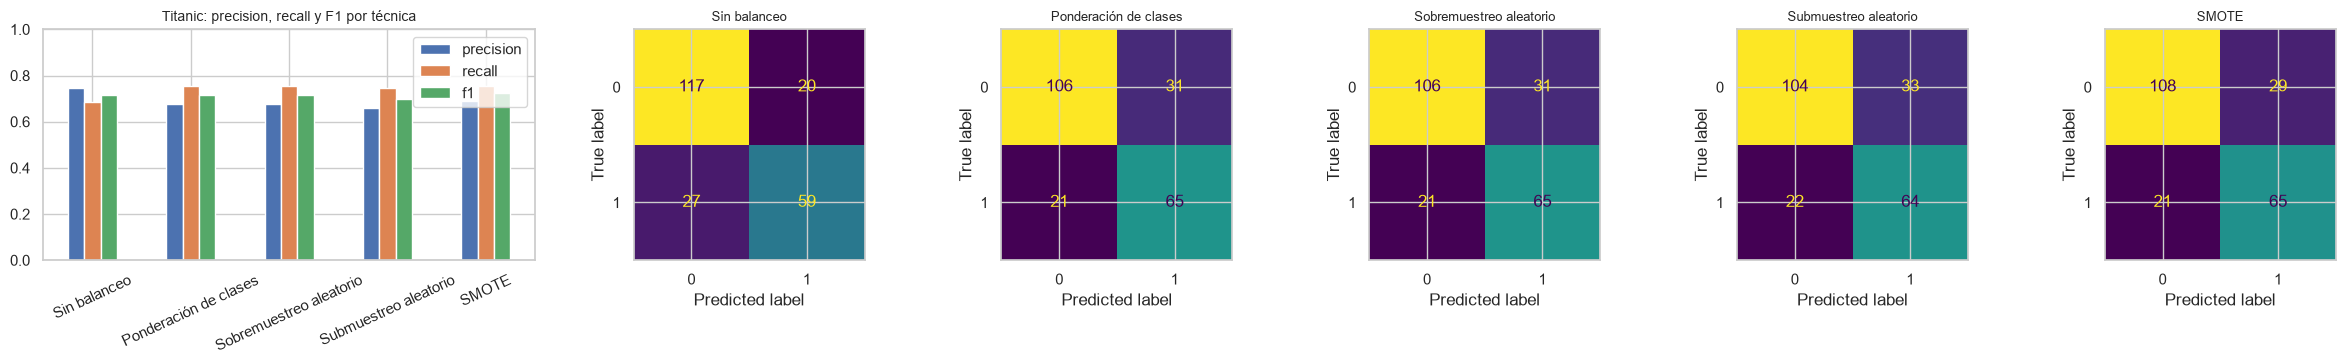

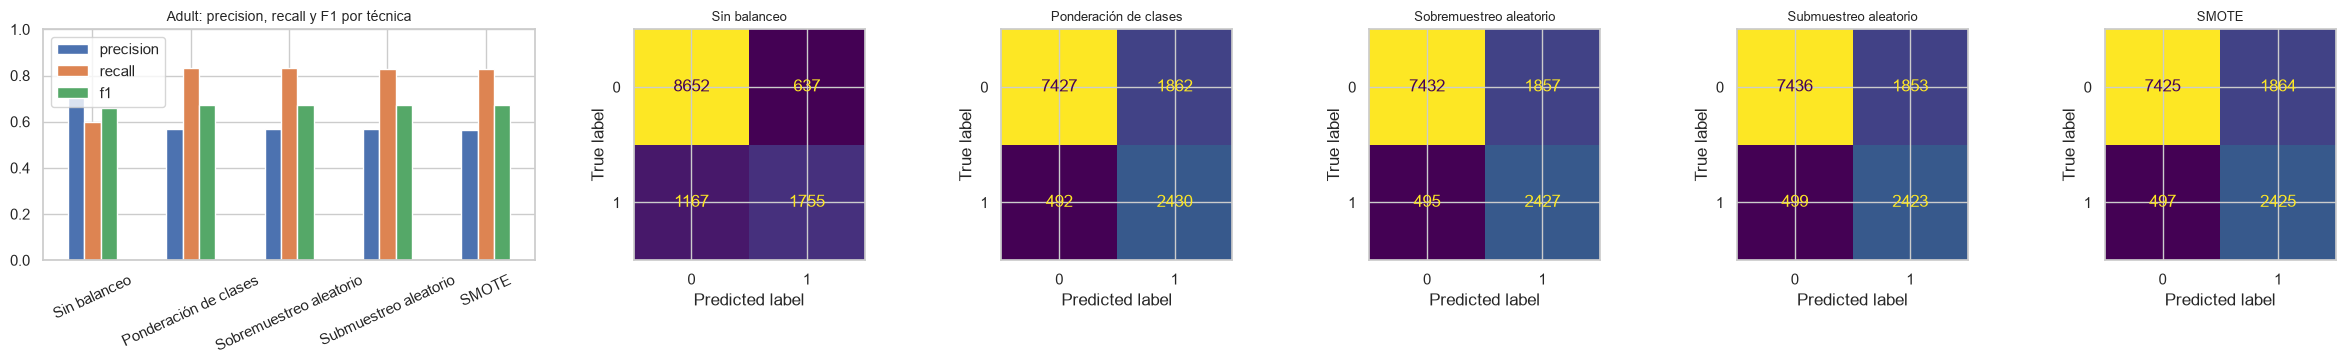

In [37]:
for nombre in D:
    res, preds, yte = BAL[nombre]["res"], BAL[nombre]["preds"], BAL[nombre]["yte"]
    fig, ax = plt.subplots(1, 6, figsize=(24, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1, 1, 1, 1, 1]))
    res[["precision", "recall", "f1"]].plot(kind="bar", ax=ax[0], rot=25)
    ax[0].set_title(f"{nombre}: precision, recall y F1 por técnica", fontsize=10)
    ax[0].set_ylim(0, 1)
    for a_, tec in zip(ax[1:], TECNICAS):
        ConfusionMatrixDisplay.from_predictions(yte, preds[tec], ax=a_, colorbar=False)
        a_.set_title(tec, fontsize=9)
    plt.tight_layout(); guardar(fig, f"balanceo_{nombre.lower()}"); plt.show()

### 7.4 Efecto sobre cada grupo

In [38]:
# ¿Qué le ocurre a cada grupo (sexo) según la técnica? (pregunta 4 de la sección 1)
for nombre, d in D.items():
    g = d["te_w"][d["grupo"]].to_numpy()
    yte = BAL[nombre]["yte"]
    filas = []
    for tec in TECNICAS:
        p = BAL[nombre]["preds"][tec]
        for grupo in np.unique(g):
            m = g == grupo
            filas.append({"tecnica": tec, "grupo": grupo,
                          "tasa de predicción positiva": p[m].mean(),
                          "recall": recall_score(yte[m], p[m], zero_division=0)})
    t = pd.DataFrame(filas).pivot(index="tecnica", columns="grupo", values=["tasa de predicción positiva", "recall"])
    print(f"\n{nombre}: grupos según '{d['grupo']}'")
    display(t.loc[TECNICAS])
    guardar_tabla(t.loc[TECNICAS], f"balanceo_{nombre.lower()}_grupos")


Titanic: grupos según 'Sex'


tasa de predicción positiva       recall      
grupo                                        female  male female  male
tecnica                                                               
Sin balanceo                                  0.825 0.091  0.912 0.241
Ponderación de clases                         0.963 0.133  1.000 0.276
Sobremuestreo aleatorio                       0.950 0.140  1.000 0.276
Submuestreo aleatorio                         0.925 0.161  0.965 0.310
SMOTE                                         0.950 0.126  1.000 0.276


Adult: grupos según 'sex'


tasa de predicción positiva       recall      
grupo                                        Female  Male Female  Male
tecnica                                                               
Sin balanceo                                  0.076 0.256  0.503 0.618
Ponderación de clases                         0.135 0.459  0.675 0.860
Sobremuestreo aleatorio                       0.132 0.460  0.671 0.860
Submuestreo aleatorio                         0.135 0.457  0.675 0.857
SMOTE                                         0.136 0.458  0.680 0.857

**Interpretación del desempeño.** Las cifras de abajo son promedios de las 10 particiones de la sección 8; la partición única de las tablas anteriores da valores muy parecidos.
- **Adult:** las cuatro técnicas de balanceo producen casi el mismo resultado: el recall de `>50K` sube de ≈ 0.60 a ≈ 0.84, la precision baja de ≈ 0.73 a ≈ 0.57, el F1 mejora de 0.659 a 0.678 y la accuracy **baja** de 0.851 a 0.808. El ROC-AUC no cambia (0.906).
  Es decir, con una regresión logística el balanceo no mejora la capacidad de ordenar casos: **desplaza el umbral de decisión**, cambiando precision por recall. Que accuracy baje no significa que el modelo empeore: detecta mucho más la clase de interés.
- **Titanic:** el recall sube de 0.69 a 0.74 y la precision baja de 0.77 a 0.70; el F1 queda igual (0.718-0.726) y la accuracy baja de 0.80 a 0.78. Con un desbalance leve (IR = 1.6) el balanceo casi no aporta.
- **Riesgos observados.** El submuestreo descarta información (en Titanic usa 512 de 668 filas de train; en Adult, 17,530 de 36,631). El sobremuestreo repite filas exactas (Adult: 55,732 filas de entrenamiento, 19,101 copias). En SMOTE, **el 26.6 % de los casos sintéticos de Adult y el 50.6 % de los de Titanic
  tienen alguna categoría con valor fraccionario** (por ejemplo, 0.4 de "Sex = male"), es decir, casos que no existen en la realidad, porque SMOTE interpola variables que son categorías. Para datos mixtos sería más apropiada una variante como SMOTE-NC.
- **Por grupo (Adult).** La tasa de predicción positiva por sexo es 7.6 % en mujeres y 25.6 % en hombres sin balanceo; con balanceo sube a ≈ 13.5 % y ≈ 46 %. El balanceo aumenta el recall de ambos grupos (mujeres 0.50 a ≈ 0.68; hombres 0.62 a ≈ 0.86), pero **la brecha relativa entre grupos se mantiene** (el modelo predice `>50K` unas 3.4 veces más en hombres),
  porque refleja la diferencia real en los datos de 1994 (10.9 % frente a 30.4 %). Balancear las clases no corrige el sesgo entre grupos.

## 8. Modelado, evaluación y robustez

Hasta ahora se evaluó con una sola partición. Para saber qué diferencias son reales y cuáles son ruido, se repite **todo el proceso** (imputación, winsorización y balanceo) con 10 particiones estratificadas distintas y se reporta **media ± desviación estándar**.
Una diferencia menor que la desviación estándar no debe interpretarse como mejora.

In [39]:
R_REPETICIONES = 10    # número de particiones train/test distintas

def un_split(nombre, semilla):
    d0 = D[nombre]
    X = pd.concat([d0["Xtr"], d0["Xte"]]).sort_index()
    y = pd.concat([d0["ytr"], d0["yte"]]).sort_index()
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=semilla)
    return dict(d0, Xtr=Xtr, Xte=Xte, ytr=ytr, yte=yte)

def repetir(nombre, R=R_REPETICIONES):
    f_imp, f_win, f_bal = [], [], []
    for s in range(R):
        d = un_split(nombre, 1000 + s)
        # (a) imputación
        for et, p in estrategias_de(nombre).items():
            tr, te, extra = imputar(d["Xtr"], d["Xte"], num_imp=d["num_imp"], cat_imp=d["cat_imp"],
                                    knn_cols=KNN_COLS[nombre], **p)
            f_imp.append({"split": s, "estrategia": et,
                          **entrenar_evaluar(tr, d["ytr"], te, d["yte"], d["num"] + extra, d["cat"])})
        tr, te, extra = imputar(d["Xtr"], d["Xte"], num_imp=d["num_imp"], cat_imp=d["cat_imp"],
                                knn_cols=KNN_COLS[nombre], **ESTRATEGIAS[FINAL_IMP])
        d["tr_imp"], d["te_imp"], d["num_final"] = tr, te, d["num"] + extra
        # (b) winsorización
        for esc in ["Sin winsorizar", "IQR", "Percentiles"]:
            if esc == "Sin winsorizar":
                tw, tew = d["tr_imp"], d["te_imp"]
            else:
                tw, tew, _ = winsorizar(d["tr_imp"], d["te_imp"], d["winsor"], esc)
            f_win.append({"split": s, "escenario": esc,
                          **entrenar_evaluar(tw, d["ytr"], tew, d["yte"], d["num_final"], d["cat"])})
        # (c) balanceo (con la winsorización final)
        d["tr_w"], d["te_w"], _ = winsorizar(d["tr_imp"], d["te_imp"], d["winsor"], CRITERIO_FINAL)
        r = ejecutar_balanceo(d, semilla=s)["res"]
        for tec, fila in r.iterrows():
            f_bal.append({"split": s, "tecnica": tec, **fila.to_dict()})
    return pd.DataFrame(f_imp), pd.DataFrame(f_win), pd.DataFrame(f_bal)

def media_desv(df, clave):
    g = df.drop(columns="split").groupby(clave, sort=False)
    return g.mean().round(3).astype(str) + " ± " + g.std().round(3).astype(str)

ROB = {}
for nombre in D:
    ROB[nombre] = repetir(nombre)
    for (tabla, clave, etiqueta) in [(ROB[nombre][0], "estrategia", "imputacion"),
                                     (ROB[nombre][1], "escenario", "winsor"),
                                     (ROB[nombre][2], "tecnica", "balanceo")]:
        mm = media_desv(tabla, clave)
        print(f"\n{nombre} - {etiqueta}: media ± desviación estándar en {R_REPETICIONES} particiones")
        display(mm)
        guardar_tabla(mm, f"robustez_{nombre.lower()}_{etiqueta}")


Titanic - imputacion: media ± desviación estándar en 10 particiones


,accuracy,precision,recall,f1,balanced_acc,roc_auc
estrategia,,,,,,
A: media / moda,0.797 ± 0.022,0.765 ± 0.048,0.688 ± 0.033,0.724 ± 0.024,0.777 ± 0.02,0.846 ± 0.016
B: mediana / 'Desconocido',0.798 ± 0.023,0.768 ± 0.047,0.687 ± 0.033,0.724 ± 0.026,0.777 ± 0.021,0.844 ± 0.017
C: KNN / moda,0.793 ± 0.024,0.76 ± 0.047,0.684 ± 0.032,0.719 ± 0.026,0.773 ± 0.022,0.845 ± 0.016
B + indicador de ausencia,0.796 ± 0.024,0.764 ± 0.049,0.688 ± 0.032,0.723 ± 0.028,0.776 ± 0.023,0.844 ± 0.017



Titanic - winsor: media ± desviación estándar en 10 particiones


,accuracy,precision,recall,f1,balanced_acc,roc_auc
escenario,,,,,,
Sin winsorizar,0.796 ± 0.024,0.764 ± 0.049,0.688 ± 0.032,0.723 ± 0.028,0.776 ± 0.023,0.844 ± 0.017
IQR,0.791 ± 0.019,0.754 ± 0.039,0.686 ± 0.033,0.717 ± 0.024,0.772 ± 0.019,0.846 ± 0.018
Percentiles,0.799 ± 0.023,0.768 ± 0.045,0.691 ± 0.034,0.726 ± 0.027,0.779 ± 0.022,0.845 ± 0.017



Titanic - balanceo: media ± desviación estándar en 10 particiones


...

,accuracy,precision,recall,f1,balanced_acc,roc_auc
estrategia,,,,,,
A: media / moda,0.85 ± 0.004,0.728 ± 0.009,0.594 ± 0.01,0.654 ± 0.009,0.762 ± 0.005,0.904 ± 0.003
B: mediana / 'Desconocido',0.851 ± 0.004,0.73 ± 0.01,0.598 ± 0.009,0.657 ± 0.008,0.764 ± 0.005,0.906 ± 0.003
B + indicador de ausencia,0.851 ± 0.003,0.73 ± 0.01,0.598 ± 0.008,0.657 ± 0.008,0.764 ± 0.005,0.905 ± 0.003



Adult - winsor: media ± desviación estándar en 10 particiones


,accuracy,precision,recall,f1,balanced_acc,roc_auc
escenario,,,,,,
Sin winsorizar,0.851 ± 0.003,0.73 ± 0.01,0.598 ± 0.008,0.657 ± 0.008,0.764 ± 0.005,0.905 ± 0.003
IQR,0.835 ± 0.003,0.692 ± 0.009,0.559 ± 0.007,0.618 ± 0.006,0.74 ± 0.004,0.886 ± 0.003
Percentiles,0.851 ± 0.004,0.732 ± 0.01,0.599 ± 0.009,0.659 ± 0.008,0.765 ± 0.005,0.906 ± 0.003



Adult - balanceo: media ± desviación estándar en 10 particiones


,accuracy,precision,recall,f1,balanced_acc,roc_auc
tecnica,,,,,,
Sin balanceo,0.851 ± 0.004,0.732 ± 0.01,0.599 ± 0.009,0.659 ± 0.008,0.765 ± 0.005,0.906 ± 0.003
Ponderación de clases,0.808 ± 0.003,0.567 ± 0.005,0.842 ± 0.009,0.678 ± 0.005,0.82 ± 0.005,0.906 ± 0.003
Sobremuestreo aleatorio,0.808 ± 0.003,0.567 ± 0.004,0.842 ± 0.01,0.678 ± 0.005,0.82 ± 0.004,0.906 ± 0.003
Submuestreo aleatorio,0.808 ± 0.003,0.566 ± 0.004,0.843 ± 0.009,0.677 ± 0.005,0.82 ± 0.004,0.906 ± 0.003
SMOTE,0.809 ± 0.003,0.567 ± 0.004,0.841 ± 0.009,0.678 ± 0.005,0.82 ± 0.005,0.905 ± 0.003


**Lectura de las tablas de robustez.**
- **Imputación:** no hay diferencias relevantes entre estrategias (Titanic: F1 0.720-0.724 ± 0.025; Adult: 0.654-0.657 ± 0.008).
- **Winsorización:** en Adult, IQR reduce el F1 de 0.657 a 0.618 (±0.007) y la accuracy de 0.851 a 0.835, una caída real; percentiles es equivalente a no winsorizar (0.659). En Titanic las diferencias son ruido.
- **Balanceo:** en Adult, el recall pasa de 0.599 ± 0.009 a 0.84 ± 0.01 y el F1 de 0.659 ± 0.008 a 0.678 ± 0.005 (mejora real, aunque pequeña); las cuatro técnicas son indistinguibles entre sí y el ROC-AUC no cambia. En Titanic el recall sube de 0.691 ± 0.034 a ≈ 0.74 ± 0.03,
  la precision baja de 0.768 a ≈ 0.70 y el F1 no mejora (0.726 frente a 0.718-0.722, dentro del ruido).

In [40]:
# Resumen global para el informe y la presentación
resumen = pd.concat({n: BAL[n]["res"][["accuracy", "precision", "recall", "f1", "balanced_acc", "roc_auc"]]
                     for n in D}, names=["dataset", "tecnica"])
display(resumen)
guardar_tabla(resumen, "resumen_balanceo")
print("\nArchivos generados en figuras/ y resultados/:")
print(sorted(os.listdir("figuras"))[:50])
print(sorted(os.listdir("resultados"))[:50])

accuracy  precision  recall    f1  balanced_acc  roc_auc
dataset tecnica                                                                          
Titanic Sin balanceo                0.789      0.747   0.686 0.715         0.770    0.834
        Ponderación de clases       0.767      0.677   0.756 0.714         0.765    0.832
        Sobremuestreo aleatorio     0.767      0.677   0.756 0.714         0.765    0.831
        Submuestreo aleatorio       0.753      0.660   0.744 0.699         0.752    0.830
        SMOTE                       0.776      0.691   0.756 0.722         0.772    0.837
Adult   Sin balanceo                0.852      0.734   0.601 0.661         0.766    0.905
        Ponderación de clases       0.807      0.566   0.832 0.674         0.816    0.905
        Sobremuestreo aleatorio     0.807      0.567   0.831 0.674         0.815    0.905
        Submuestreo aleatorio       0.807      0.567   0.829 0.673         0.815    0.905
        SMOTE                       0.807      0.565   0.830 0.673         0.815    0.904


Archivos generados en figuras/ y resultados/:
['adult_1_distribuciones.png', 'adult_1b_capital.png', 'adult_2_boxplots.png', 'adult_3_categoricas.png', 'adult_4_correlacion.png', 'adult_5_relaciones.png', 'balanceo_adult.png', 'balanceo_titanic.png', 'imputacion_categoricas.png', 'titanic_1_distribuciones.png', 'titanic_2_boxplots.png', 'titanic_3_categoricas.png', 'titanic_4_correlacion.png', 'titanic_5_relaciones.png', 'titanic_imputacion_age.png', 'winsor_adult_capital-gain.png', 'winsor_adult_hours-per-week.png', 'winsor_titanic_Fare.png']
['balanceo_adult_grupos.csv', 'balanceo_adult_metricas.csv', 'balanceo_titanic_grupos.csv', 'balanceo_titanic_metricas.csv', 'imputacion_adult_native-country_frecuencias.csv', 'imputacion_adult_occupation_frecuencias.csv', 'imputacion_adult_workclass_frecuencias.csv', 'imputacion_desempeno.csv', 'imputacion_titanic_Deck_frecuencias.csv', 'imputacion_titanic_Embarked_frecuencias.csv', 'imputacion_titanic_age_distribucion.csv', 'perfil_adult_categ

## 9. Conclusiones y recomendación

**Hallazgos de EDA que más pesan.**
1. En Titanic, la supervivencia depende fuertemente de sexo y clase (97 % de las mujeres de primera frente a 13 % de los hombres de tercera) y de la edad de forma no lineal; `Cabin` falta en 77 % de los casos y su presencia revela información del proceso de recolección (posible fuga).
2. En Adult, `capital-gain` y `capital-loss` son casi siempre cero y tienen valores tope (99999); `education` y `education-num` son idénticas; los faltantes (≈ 6 %) están en `workclass` y `occupation` a la vez.

**Decisiones y justificación.**
| Etapa | Decisión | Evidencia |
|---|---|---|
| Imputación | Mediana / "Desconocido" + indicador de ausencia | La moda crea concentraciones artificiales (Deck C pasa de 5.7 % a 83.8 %); el desempeño es equivalente en las tres estrategias. |
| Outliers | Winsorización por percentiles 1-99 en variables continuas | El IQR colapsa `capital-gain` y `capital-loss` a 0 y baja el F1 de 0.657 a 0.618 en Adult; percentiles no pierde desempeño. |
| Desbalance | Ponderación de clases (`class_weight="balanced"`) si el objetivo es detectar la clase positiva | Obtiene el mismo resultado que sobremuestreo, submuestreo y SMOTE (en Adult recall 0.84 y F1 0.678), sin duplicar filas, sin descartar datos y sin crear casos sintéticos. |

**Recomendación.** Usar el pipeline: separación estratificada, luego imputación B + indicador, winsorización por percentiles y ponderación de clases, y evaluar con precision, recall y F1 (no accuracy). La técnica de balanceo debe elegirse según el costo de cada error:
si pasar por alto un positivo es más grave, se prefiere el recall alto (con balanceo); si los falsos positivos son costosos, la línea base con mayor precision es mejor. Como el balanceo equivale a mover el umbral de decisión, ajustar el umbral con los costos reales es una alternativa más directa.

**Limitaciones.**
- Se usa un solo clasificador (regresión logística); con árboles o con modelos más flexibles el efecto de los outliers y de la imputación podría ser distinto, y el de la winsorización sería casi nulo (los árboles no dependen de la escala).
- Las comparaciones de Titanic tienen poca potencia (223 casos de prueba); por eso se usaron 10 particiones, aunque con una sola partición de entrenamiento y prueba por repetición.
- La imputación numérica solo se pudo comparar en Titanic (Adult no tiene faltantes numéricos). Se podría simular una pérdida de valores en una variable de Adult para evaluarla, pero eso quedó fuera del alcance.
- SMOTE se aplicó sobre variables codificadas con one-hot, lo que crea categorías fraccionarias; SMOTE-NC sería más apropiado.
- No se aplicó ninguna mitigación de sesgo entre grupos (sexo, raza) y los datos de Adult son de 1994; el modelo no debe usarse para decisiones reales sobre personas.
- Los porcentajes y métricas citados en las interpretaciones provienen de la ejecución con `SEED = 42`; con otras versiones de las librerías pueden variar levemente, por lo que conviene verificarlos contra las tablas generadas.